In [16]:
# This code defines the functions to simulated XRD and M-B datasets for iron oxide nanoparticles
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import k as k_B, mu_0, pi
from pymatgen.core import Structure
from pymatgen.analysis.diffraction.xrd import XRDCalculator
from pathlib import Path

# Folder containing the CIF files
CIF_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\CIF"
)

# Load CIF structures 
fe3o4_struct = Structure.from_file(CIF_DIR/"1010369_Fe3O4.cif")
feo_struct   = Structure.from_file(CIF_DIR/"1011169_FeO.cif")
#feo_struct   = Structure.from_file("9015696_Fe2O3.cif")
#alphaFe2O3_struct   = Structure.from_file("1011240_Hematite.cif") # not used currently


# Simulated normalized XRD for Fe3O4/FeO mixing using scherrer broadening for each phase, intrumental broadening (in quadrature) and Pseudo-Voigt peak shapes
def simulate_xrd_fe3o4_feo(grain_size_fe3o4_nm,
                           grain_size_feo_nm,
                           phase_frac_fe3o4,
                           two_theta_range=(25, 65),
                           num_points=2000,
                           K=0.9,
                           wavelength=1.54184,
                           instr_fwhm_deg=0.02): 
    
    calc = XRDCalculator(wavelength="CuKa")
    two_theta = np.linspace(*two_theta_range, num_points)
    intensity = np.zeros_like(two_theta)

    # Define mapping from structure to size and phase fraction
    phases = [
        (fe3o4_struct, phase_frac_fe3o4, grain_size_fe3o4_nm),
        (feo_struct,   1 - phase_frac_fe3o4, grain_size_feo_nm)
    ]

    for struct, frac, gs_nm in phases:
        pat = calc.get_pattern(struct, two_theta_range=two_theta_range)
        D_A = gs_nm * 10.0  # convert nm to anstrom
        for x0, I0 in zip(pat.x, pat.y):
            theta0 = np.radians(x0 / 2)
            # Scherrer size broadening
            beta_size_rad = (K * wavelength) / (D_A * np.cos(theta0))
            beta_size_deg = beta_size_rad * 180 / np.pi
            # Total FWHM
            beta_total = np.sqrt(beta_size_deg**2 + instr_fwhm_deg**2)
            # Pseudo-Voigt
            sigma_G = beta_total / (2 * np.sqrt(2 * np.log(2)))
            gamma_L = beta_total / 2
            eta = 0.3 #Gaussian and Lorentzian mixing parameter
            diff = two_theta - x0
            G = np.exp(-diff**2 / (2 * sigma_G**2)) / (sigma_G * np.sqrt(2 * np.pi))
            L = (1 / np.pi) * (gamma_L / (diff**2 + gamma_L**2))
            
            intensity += frac * I0 * (eta * L + (1 - eta) * G)

    # Normalize to max = 1
    intensity /= intensity.max()
    return two_theta, intensity

# Simulate Langevin model for Fe3O4, surface defect effect/ spin canting for scaling Ms(D), linear paramagnetic FeO contribution, returns field array (T) and total magnetization in (Am^2/kg)
def simulate_hysteresis_langevin(grain_size_nm,
                                      phase_frac_fe3o4,
                                      spin_canting_layer_nm=0.3, # Could be tuned depending on experimental data, 0.3 used for paper
                                      chi_mass=1e-6,
                                      T=300.0,
                                      B_min=-2.8,
                                      B_max=2.8,
                                      n_points=300):

    # Size-dependent Ms via core–shell surface layer
    Ms_bulk = 92.0  # Am^2/kg
    d, t = grain_size_nm, spin_canting_layer_nm
    Ms_size = 0.0 if d <= 2*t else Ms_bulk * ((d - 2*t)/d)**3

    # Paramagnetic FeO 
    slope_para = chi_mass/ mu_0

    # Effective moment per particle
    r      = 0.5 * d * 1e-9         # radius in m
    V      = (4/3) * pi * r**3      # volume in m^3
    rho    = 5200.0                 # kg/m^3
    m_p    = rho * V                # kg
    mu_eff = Ms_size * m_p          # Am^2

    # Field grid
    B = np.linspace(B_min, B_max, n_points)

    # Langevin function
    x = mu_eff * B / (k_B * T)
    L = np.zeros_like(x)
    mask = np.abs(x) > 1e-8
    L[mask] = 1/np.tanh(x[mask]) - 1/x[mask]

    # Mixed phased magnetization
    M_spm  = phase_frac_fe3o4 * Ms_size * L
    M_para = (1 - phase_frac_fe3o4) * slope_para * B
    M_tot  = M_spm + M_para

    return B, M_tot

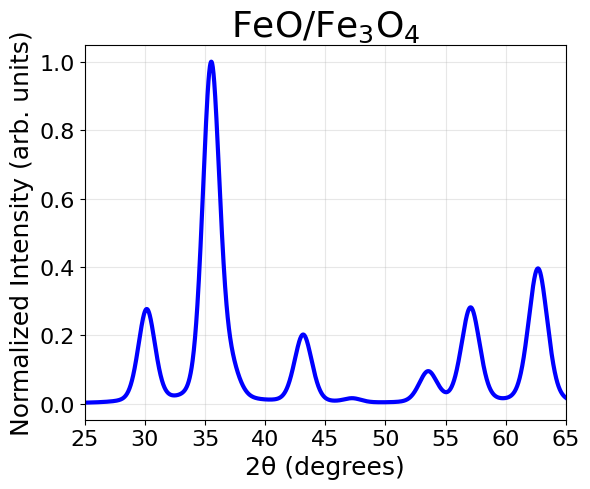

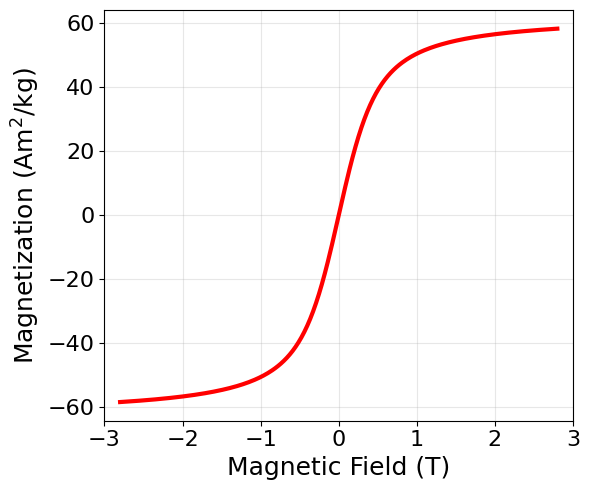

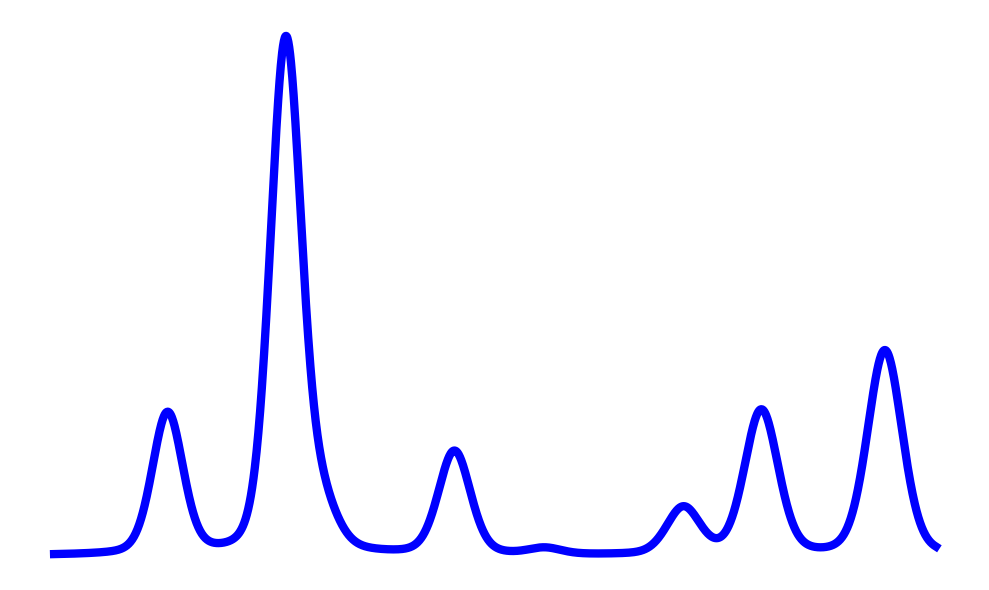

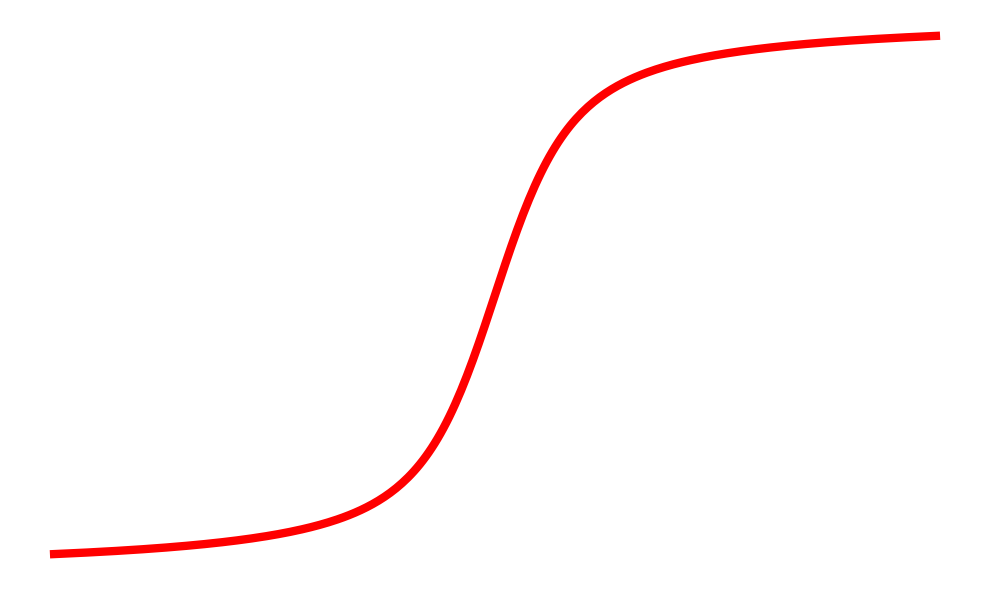

In [18]:
# This code plots XRD and M-H datsasets that can be generated from the simulation functions

import matplotlib.pyplot as plt

# Sample parameters 
grain_size_fe3o4 = 5 # Fe3O4 grain size in nm
grain_size_feo   = 10 # FeO grain size in nm 
phase_frac       = 1.0 # fraction of Fe3O4 (0-1)

# fig1/fig2 15 nm, 1 (a), 10 nm, 0 (b), 5 nm Fe3O4/ 10 nm FeO, 0.3, fig1 uses 10,6 aspect ratio

# TOC used 5 nm, 10 nm, 0.5 and 15 nm, 5 nm, 0.95 

# Simulate XRD
two_theta, xrd_intensity = simulate_xrd_fe3o4_feo(
    grain_size_fe3o4_nm=grain_size_fe3o4,
    grain_size_feo_nm=grain_size_feo,
    phase_frac_fe3o4=phase_frac
)

# Simulate Langevin-paramagnetic M–H curve
B_field, M_curve = simulate_hysteresis_langevin(
    grain_size_nm=grain_size_fe3o4,
    phase_frac_fe3o4=phase_frac
)

# Plot side by side 
#fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Font size parameters
label_fontsize = 16
tick_fontsize = 14
title_fontsize = 16

# XRD plot combined plots, not used
#ax1.plot(two_theta, xrd_intensity, lw=2.0, color='tab:blue')
#ax1.set_xlabel('2θ (degrees)', fontsize=label_fontsize)
#ax1.set_ylabel('Normalized Intensity (arb. units)', fontsize=label_fontsize)
#ax1.set_title(
#    f'Fe₃O₄ {phase_frac*100:.0f}% ({grain_size_fe3o4:.0f} nm), '
#    f'FeO {(1-phase_frac)*100:.0f}% ({grain_size_feo:.0f} nm)',
#    fontsize=title_fontsize
#)
#ax1.set_xticks([25, 30, 35, 40, 45, 50, 55, 60, 65])
#ax1.set_yticks([0.0, 0.25, 0.5, 0.75, 1.0])
#ax1.tick_params(axis='both', labelsize=tick_fontsize)
#ax1.grid(True)

# M–H plot
#ax2.plot(B_field, M_curve, lw=2.0, color='tab:red')
#ax2.set_xlabel('Magnetic Field (T)', fontsize=label_fontsize)
#ax2.set_ylabel('Magnetization (Am$^2$/kg)', fontsize=label_fontsize)
#ax2.set_title(
#    f'Fe₃O₄ {phase_frac*100:.0f}% ({grain_size_fe3o4:.0f} nm), '
#    f'FeO {(1-phase_frac)*100:.0f}% ({grain_size_feo:.0f} nm)',
#    fontsize=title_fontsize
#)
#ax2.tick_params(axis='both', labelsize=tick_fontsize)
#ax2.set_xticks([-3, -1.5, 0, 1.5, 3])
#ax2.grid(True)

# Seperate plots

# XRD plot
plt.figure(figsize=(6, 5))
plt.plot(two_theta, xrd_intensity, lw=3, color="b", alpha = 1.0)
plt.xlabel("2θ (degrees)", fontsize=18)
plt.xlim(25, 65)
plt.ylabel("Normalized Intensity (arb. units)", fontsize=18)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
#plt.title("FeO", fontsize=26)
plt.title("FeO/Fe$_3$O$_4$", fontsize=26)
#plt.title("Fe$_3$O$_4$", fontsize=26)
#plt.legend(fontsize=14)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# M-H plot
plt.figure(figsize=(6, 5))
plt.plot(B_field, M_curve, lw=3, color="r")
plt.xlabel("Magnetic Field (T)", fontsize=18)
plt.xlim(-3, 3)
plt.ylabel("Magnetization (Am$^2$/kg)", fontsize=18)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
#plt.legend(fontsize=14)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# XRD curve only, for workflow schematic 
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(two_theta, xrd_intensity, lw=6, color="b")

ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("")
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_facecolor("white")
fig.patch.set_facecolor("white")

plt.tight_layout()
# fig.savefig("xrd_curve_only.png", dpi=300, bbox_inches="tight")
plt.show()

# Minimal M–B curve only
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(B_field, M_curve, lw=6, color="r")

# Remove everything except the curve
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("")
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_facecolor("white")
fig.patch.set_facecolor("white")

plt.tight_layout()
# fig.savefig("mh_curve_only.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
# Generates simulated dataset of size N, stores as .npz and JSON

import json
import numpy as np
from pathlib import Path

# Directory where generated datasets will be saved
OUTPUT_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Simulated_datasets"
)

# Create the directory if it does not already exist
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 123 # for reproducible distributions, used in paper 1, 22, 42, 80, 123 (added on post accepted revisions). 
np.random.seed(RANDOM_SEED)
    
# Dataset size
N = 1000 # To reproduce data used in the paper, generated data of size N = 20, 25, 50, 100, 500, 1000, 5000, 10000 for a random seed of 42
         # generate datasets of N = 1000 for random seeds 1, 22, 80

file_stem = f"fe3o4_feo_dataset_N_{N}_r_{RANDOM_SEED}"

# Sample random parameters 
grain_sizes_fe3o4 = np.random.uniform(3.0, 50.0, size=N)  # Fe3O4 grain/crystallite size (nm)
grain_sizes_feo   = np.random.uniform(3.0, 50.0, size=N)  # FeO grain/crystallite size (nm)
phase_fracs       = np.random.uniform(0.0, 1.0, size=N)   # Fe3O4 fraction 

# Grid sizes
theta_grid, _ = simulate_xrd_fe3o4_feo(
    grain_size_fe3o4_nm=grain_sizes_fe3o4[0],
    grain_size_feo_nm=  grain_sizes_feo[0],
    phase_frac_fe3o4=  phase_fracs[0]
)
n_xrd = theta_grid.size

B_grid, _ = simulate_hysteresis_langevin(
    grain_size_nm=      grain_sizes_fe3o4[0],
    phase_frac_fe3o4=   phase_fracs[0]
)
n_hyst = B_grid.size

# Preallocate storage 
xrd_data = np.zeros((N, n_xrd), dtype=np.float32)
mh_data  = np.zeros((N, n_hyst), dtype=np.float32)

# labels: [D_Fe3O4, D_FeO, frac_Fe3O4, max_M]
labels   = np.zeros((N, 4), dtype=np.float32)

# Generate dataset 
for i in range(N):
    d1 = grain_sizes_fe3o4[i]
    d2 = grain_sizes_feo[i]
    f  = phase_fracs[i]

    # XRD simulation
    _, I = simulate_xrd_fe3o4_feo(
        grain_size_fe3o4_nm = d1,
        grain_size_feo_nm = d2,
        phase_frac_fe3o4 = f
    )
    xrd_data[i, :] = I

    # M vs. H simulation
    _, M = simulate_hysteresis_langevin(
        grain_size_nm=    d1,
        phase_frac_fe3o4= f
    )
    mh_data[i, :] = M

    # Store labels
    labels[i, 0] = d1          # Fe3O4 size
    labels[i, 1] = d2          # FeO size
    labels[i, 2] = f           # Fe3O4 fraction
    labels[i, 3] = M.max()     # Max magnetization/ magnetization at 2.8T

# Save data

npz_path = OUTPUT_DIR / f"{file_stem}.npz"
json_path = OUTPUT_DIR / f"{file_stem}.json"

np.savez(npz_path,
         two_theta=theta_grid,
         B_field=B_grid,
         xrd=xrd_data,
         M_hysteresis=mh_data,
         labels=labels)

print(f"Saved {N} samples to:")
print(npz_path)


# Save data as JSON

samples = []
for i in range(N):
    samples.append({
        "id": int(i),
        "xrd": xrd_data[i].tolist(),
        "mh":  mh_data[i].tolist(),   
        "labels": {
            "D_Fe3O4_nm": float(labels[i, 0]),
            "D_FeO_nm":   float(labels[i, 1]),
            "frac_Fe3O4": float(labels[i, 2]),
            "max_M":      float(labels[i, 3]),
        }
    })

payload = {
    "two_theta": theta_grid.tolist(),
    "B_field": B_grid.tolist(),
    "samples": samples
}

with json_path.open("w", encoding="utf-8") as f:
    json.dump(payload, f, ensure_ascii=False, indent=2)

print("Saved JSON dataset to:")
print(json_path)

findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


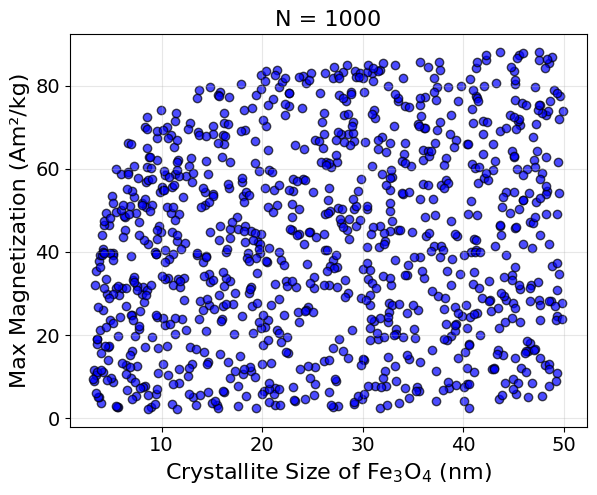

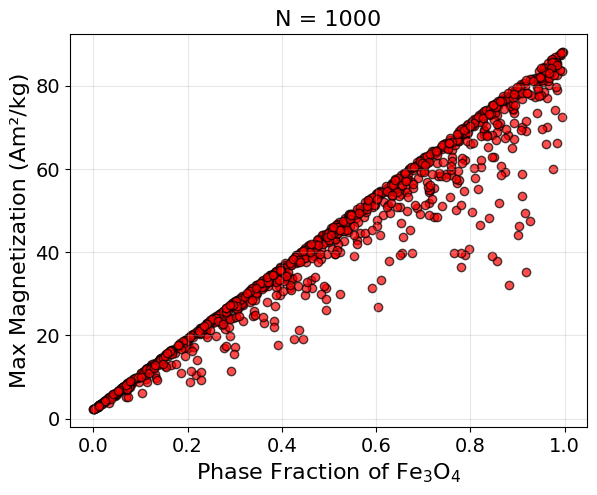

In [1]:
# Visulization of datasets

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Simulated_datasets"
)

DATA_FILE = "fe3o4_feo_dataset_N_1000_r_42.npz"
data_path = DATA_DIR / DATA_FILE

# Confirm that the dataset exists before loading
if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found:\n{data_path}")


# Load simulate data
data = np.load(data_path)
labels = data['labels']
# columns: [D_Fe3O4, D_FeO, frac_Fe3O4, M]
grain_sizes_fe3o4 = labels[:, 0]
fe3o4_fractions   = labels[:, 2]
M_values          = labels[:, 3]

# Plot Magnetization at 2.8 T vs. Fe3O4 crystallite size
plt.figure(figsize=(6, 5))
plt.scatter(grain_sizes_fe3o4, M_values, c="b", edgecolors='k', alpha=0.7)
plt.xlabel('Crystallite Size of Fe$_3$O$_4$ (nm)', fontsize=16)
plt.ylabel('Max Magnetization (Am²/kg)', fontsize=16)
plt.title('N = 1000', fontsize=16)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

# Plot Magnetization vs. Fe3O4 phase fraction
plt.figure(figsize=(6, 5))
plt.scatter(fe3o4_fractions, M_values, c="r", edgecolors='k', alpha=0.7)
plt.xlabel('Phase Fraction of Fe$_3$O$_4$', fontsize=16)
plt.ylabel('Max Magnetization (Am²/kg)', fontsize=16)
plt.title('N = 1000', fontsize=16)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

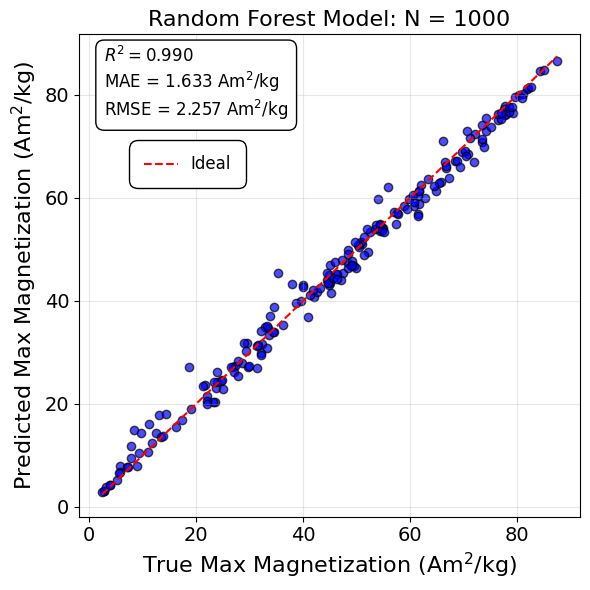

Random Forest model saved to:
C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Trained_models\rf_model_fe3o4_feo_dataset_N_1000_r_42_v2.pkl


In [11]:
# Trains a random forest regression model using the simulated dataset

import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Simulated_datasets"
)

MODEL_OUTPUT_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Trained_models"
)

MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_FILE = "rf_model_fe3o4_feo_dataset_N_1000_r_42_v2.pkl"
DATA_FILE = "fe3o4_feo_dataset_N_1000_r_42.npz"

data_path = DATA_DIR / DATA_FILE
model_path = MODEL_OUTPUT_DIR / MODEL_FILE


# Confirm that the dataset exists before loading
if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found:\n{data_path}")


#  Load simulated dataset
data = np.load(data_path) 
X = data['xrd'] # shape (N, n_xrd)
y = data['labels'][:, 3] # max magnetization 

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

# Train Random Forest
rf = RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=3,      
    max_features="sqrt",  # v1 0.3, v2 sqrt, v3 0.05  
    random_state=1,
    n_jobs=-1,
)
rf.fit(X_train, y_train)

# Predict on test set
y_pred = rf.predict(X_test)

# Compute metrics
r2   = r2_score(y_test, y_pred)
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Plot predicted vs. true
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, c="b", alpha=0.7, edgecolor='k')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', label='Ideal')
#plt.xlim(lims), # added in revisions, not really needed
#plt.ylim(lims), # added in revisions, not really needed
plt.xlabel('True Max Magnetization (Am$^2$/kg)', fontsize=16)
plt.ylabel('Predicted Max Magnetization (Am$^2$/kg)', fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.title('Random Forest Model: N = 1000', fontsize=16)

textstr = '\n'.join((
    f'$R^2 = {r2:.3f}$',
    f'MAE = {mae:.3f} Am$^2$/kg',
    f'RMSE = {rmse:.3f} Am$^2$/kg',
))
plt.text(0.05, 0.975, textstr, transform=plt.gca().transAxes,
         fontsize=12, verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=1.0))

legend = plt.legend(loc='upper left', bbox_to_anchor=(0.1, 0.78),
                    fontsize=12, frameon=True)

frame = legend.get_frame()
frame.set_facecolor('white')
frame.set_edgecolor('black')
frame.set_alpha(1.0)
frame.set_linewidth(1.0)
frame.set_boxstyle("round,pad=0.5") 

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Save the trained model as .pkl
joblib.dump(rf, model_path)
print("Random Forest model saved to:")
print(model_path)

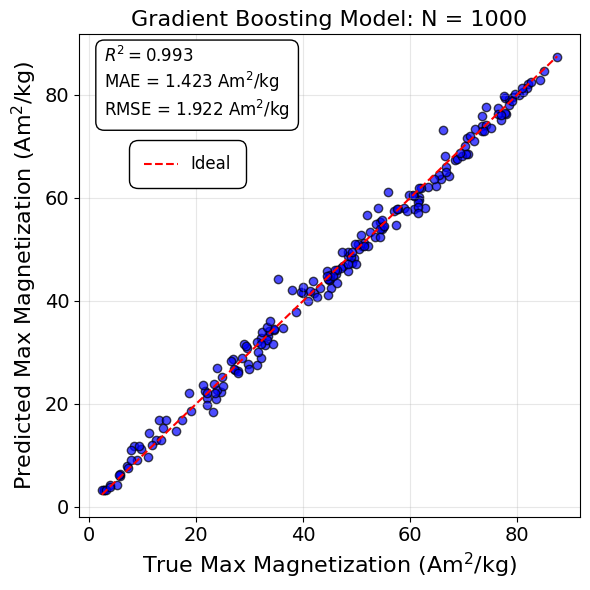

Gradient Boosting model saved to:
C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Trained_models\gb_model_fe3o4_feo_dataset_N_1000_r_42_v5.pkl


In [10]:
# Trains a gradient boosting regression model using the simulated dataset

import numpy as np
import matplotlib.pyplot as plt
import joblib
import matplotlib.patches as mpatches
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from pathlib import Path


DATA_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Simulated_datasets"
)

MODEL_OUTPUT_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Trained_models"
)

MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_FILE = "gb_model_fe3o4_feo_dataset_N_1000_r_42_v5.pkl"
DATA_FILE = "fe3o4_feo_dataset_N_1000_r_42.npz"

data_path = DATA_DIR / DATA_FILE
model_path = MODEL_OUTPUT_DIR / MODEL_FILE



# Confirm that the dataset exists before loading
if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found:\n{data_path}")


# Load simulated dataset
data = np.load(data_path) 
X = data['xrd'] # shape (N, n_xrd)
y = data['labels'][:, 3] # Max Magnetization

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

# Train Gradient Boosting

# v1 conditions
#gb = GradientBoostingRegressor(
#        n_estimators=500,
#        learning_rate=0.05,
#        max_depth=3,
#        random_state=1)

# v2 conditions
#gb = GradientBoostingRegressor(
#    n_estimators=500,
#    learning_rate=0.05,
#    max_depth=3,
#    subsample=0.8,        
#    min_samples_leaf=5,   
#    random_state=1
#)

# v3/v4/5 conditions
gb = GradientBoostingRegressor(
    n_estimators=800,          #
    learning_rate=0.03,        
    # tree shape / regularization
    max_depth=3,
    min_samples_leaf=5,
    max_features=0.3,       # v5 0.3 v3 "sqrt"
    subsample=0.8,          
    loss="huber",              # v3/v5"huber" or v4"squared_error" 
    alpha=0.9,                 # Huber’s quantile
    # gentle early stopping to prevent overfitting
    validation_fraction=0.1,   # uses 10% of training data as dev set
    n_iter_no_change=20,       # stop if no dev improvement
    tol=1e-4,
    random_state=1
)

gb.fit(X_train, y_train)

# Predict on test set
y_pred = gb.predict(X_test)

# Compute metrics
r2   = r2_score(y_test, y_pred)
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Plot predicted vs. true
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, c="b", alpha=0.7, edgecolor='k')

lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', label='Ideal') 
plt.xlabel('True Max Magnetization (Am$^2$/kg)', fontsize=16)
plt.ylabel('Predicted Max Magnetization (Am$^2$/kg)', fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.title('Gradient Boosting Model: N = 1000', fontsize=16)

textstr = '\n'.join((
    f'$R^2 = {r2:.3f}$',
    f'MAE = {mae:.3f} Am$^2$/kg',
    f'RMSE = {rmse:.3f} Am$^2$/kg',
))
plt.text(0.05, 0.975, textstr, transform=plt.gca().transAxes,
         fontsize=12, verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=1.0))

legend = plt.legend(loc='upper left', bbox_to_anchor=(0.1, 0.78),
                    fontsize=12, frameon=True)
frame = legend.get_frame()
frame.set_facecolor('white')
frame.set_edgecolor('black')
frame.set_alpha(1.0)
frame.set_linewidth(1.0)
frame.set_boxstyle("round,pad=0.5")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Save the trained model as .pkl
joblib.dump(gb, model_path)
print("Gradient Boosting model saved to:")
print(model_path)

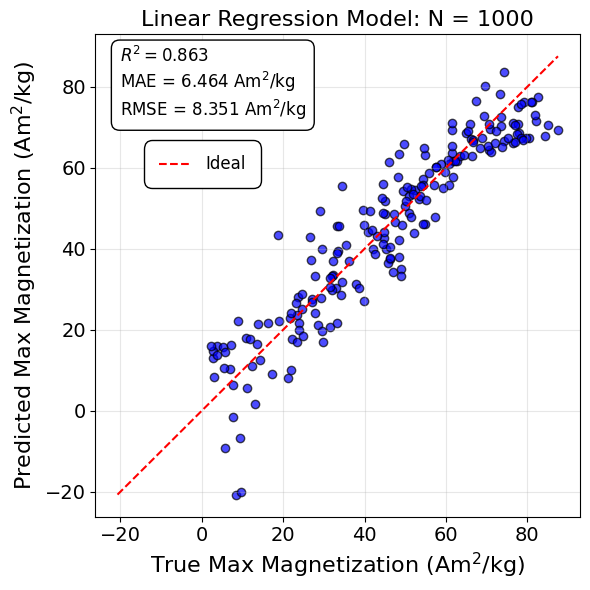

Linear Regression model saved to C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Trained_models\linear_regression_model_fe3o4_feo_dataset_N_1000_r_42_v2.pkl


In [6]:
# new code added for JPCC review

# Trains a linear regression model using the simulated dataset

import numpy as np
import matplotlib.pyplot as plt
import joblib
import matplotlib.patches as mpatches
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

PROJECT_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured"
)

DATA_DIR = PROJECT_DIR / "Simulated_datasets"
MODEL_OUTPUT_DIR = PROJECT_DIR / "Trained_models"

DATA_FILE = "fe3o4_feo_dataset_N_1000_r_42.npz"
MODEL_FILE = "linear_regression_model_fe3o4_feo_dataset_N_1000_r_42_v2.pkl"

data_path = DATA_DIR / DATA_FILE
model_path = MODEL_OUTPUT_DIR / MODEL_FILE

MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found:\n{data_path}")

# Load simulated dataset
data = np.load(data_path)
X = data['xrd']              # shape (N, n_xrd)
y = data['labels'][:, 3]     # max magnetization

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

# Train Linear Regression
lr = LinearRegression(
    fit_intercept=True,
    copy_X=True,
    #positive=True #v1
    positive=False #v2
)
lr.fit(X_train, y_train)

# Predict on test set
y_pred = lr.predict(X_test)

# Compute metrics
r2   = r2_score(y_test, y_pred)
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Plot predicted vs. actual
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, c="b", alpha=0.7, edgecolor='k')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', label='Ideal')
#plt.xlim(lims)
#plt.ylim(lims)
#plt.gca().set_aspect("equal", adjustable="box")
plt.xlabel('True Max Magnetization (Am$^2$/kg)', fontsize=16)
plt.ylabel('Predicted Max Magnetization (Am$^2$/kg)', fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.title('Linear Regression Model: N = 1000', fontsize=16)

textstr = '\n'.join((
    f'$R^2 = {r2:.3f}$',
    f'MAE = {mae:.3f} Am$^2$/kg',
    f'RMSE = {rmse:.3f} Am$^2$/kg',
))
plt.text(0.05, 0.975, textstr, transform=plt.gca().transAxes,
         fontsize=12, verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=1.0))

legend = plt.legend(loc='upper left', bbox_to_anchor=(0.1, 0.78),
                    fontsize=12, frameon=True)

frame = legend.get_frame()
frame.set_facecolor('white')
frame.set_edgecolor('black')
frame.set_alpha(1.0)
frame.set_linewidth(1.0)
frame.set_boxstyle("round,pad=0.5")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Save the trained model as .pkl
joblib.dump(lr, model_path)
print(f"Linear Regression model saved to {model_path}")

Epoch 1/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 1670.2786 - mae: 33.3391 - val_loss: 511.4083 - val_mae: 17.9531
Epoch 2/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 547.2961 - mae: 19.5532 - val_loss: 274.1662 - val_mae: 13.9049
Epoch 3/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 232.3416 - mae: 12.1503 - val_loss: 111.5441 - val_mae: 8.4048
Epoch 4/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 88.6134 - mae: 7.3665 - val_loss: 55.1981 - val_mae: 5.7875
Epoch 5/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 68.5596 - mae: 6.4072 - val_loss: 51.2974 - val_mae: 5.6709
Epoch 6/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 64.1793 - mae: 6.2639 - val_loss: 43.1971 - val_mae: 5.2462
Epoch 7/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 58.5919 - mae: 6.0296 - val_loss: 34.8703 - val_mae: 4.6632
Epoch 8/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 51.9632 - mae: 5.7017 - val_loss: 29.4332 - val_mae: 4.2746
Epoch 9/200
20/20 ━━━━━━━━━━

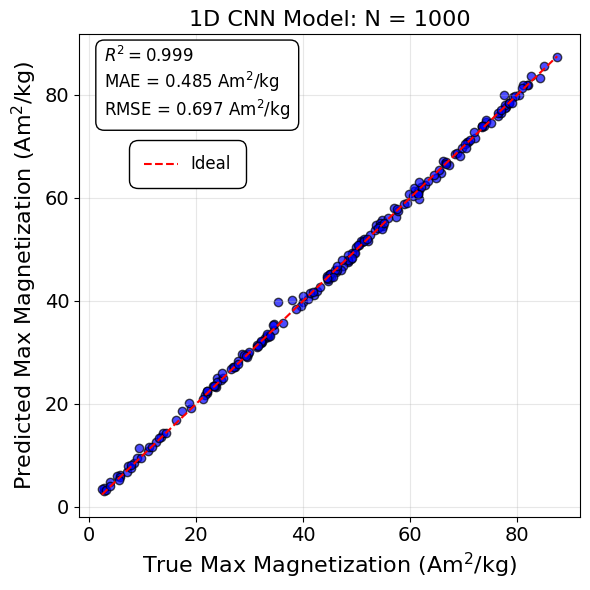

CNN model saved to:
C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Trained_models\cnn_model_fe3o4_feo_dataset_N_1000_r_42_v3.keras
CNN metadata saved to:
C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Trained_models\cnn_model_fe3o4_feo_dataset_N_1000_r_42_v3.meta.npz


In [9]:
# new code added for JPCC review

# Trains a 1D convolutional neural network (CNN) regression model using the simulated dataset, updated from first version to make deterministic based of inital seed of CNN

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import joblib
import matplotlib.patches as mpatches
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    Flatten,
    Dense,
    Dropout,
    GlobalAveragePooling1D,
    GlobalMaxPooling1D,
)
from tensorflow.keras.callbacks import EarlyStopping

# Use a font that is available to avoid matplotlib font fallback warnings
mpl.rcParams['font.family'] = 'DejaVu Sans'


PROJECT_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured"
)

DATA_DIR = PROJECT_DIR / "Simulated_datasets"
MODEL_OUTPUT_DIR = PROJECT_DIR / "Trained_models"

DATA_FILE = "fe3o4_feo_dataset_N_1000_r_42.npz"
MODEL_FILE = "cnn_model_fe3o4_feo_dataset_N_1000_r_42_v3.keras"

data_path = DATA_DIR / DATA_FILE
model_path = MODEL_OUTPUT_DIR / MODEL_FILE
metadata_path = model_path.with_suffix(".meta.npz")

MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found:\n{data_path}")


# Reproducibility

SEED = 2
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()


# Load simulated dataset
data = np.load(data_path)
X = data['xrd']              # shape (N, n_xrd)
y = data['labels'][:, 3]     # max magnetization
two_theta = data["two_theta"]


# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

# Reshape for CNN input: (samples, length, channels)
X_train_cnn = X_train[..., np.newaxis]
X_test_cnn  = X_test[..., np.newaxis]

# Train CNN
cnn = Sequential([
    Input(shape=(X_train_cnn.shape[1], 1)),
    Conv1D(filters=32, kernel_size=5, activation='relu'),
    MaxPooling1D(pool_size=2),

    Conv1D(filters=64, kernel_size=5, activation='relu'),
    MaxPooling1D(pool_size=2),

    Conv1D(filters=128, kernel_size=5, activation='relu'),
    #GlobalAveragePooling1D(), # v1 using GlobalAverage
    #GlobalMaxPooling1D(), # v2 using GlobalMaxPooling
    MaxPooling1D(pool_size=2), # V3 use MaxPooling1D

    Flatten(), # V3 need to use for MaxPoolings1D
    Dense(64, activation='relu'),
    Dense(1)
])

cnn.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)

history = cnn.fit(
    X_train_cnn, y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

print(f"Best epoch: {best_epoch}")

# Predict on test set
y_pred = cnn.predict(X_test_cnn, verbose=0).reshape(-1)

# Compute metrics
r2   = r2_score(y_test, y_pred)
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Plot predicted vs. true
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, c="b", alpha=0.7, edgecolor='k')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', label='Ideal')
plt.xlabel('True Max Magnetization (Am$^2$/kg)', fontsize=16)
plt.ylabel('Predicted Max Magnetization (Am$^2$/kg)', fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.title('1D CNN Model: N = 1000', fontsize=16)

textstr = '\n'.join((
    f'$R^2 = {r2:.3f}$',
    f'MAE = {mae:.3f} Am$^2$/kg',
    f'RMSE = {rmse:.3f} Am$^2$/kg',
))
plt.text(0.05, 0.975, textstr, transform=plt.gca().transAxes,
         fontsize=12, verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=1.0))

legend = plt.legend(loc='upper left', bbox_to_anchor=(0.1, 0.78),
                    fontsize=12, frameon=True)

frame = legend.get_frame()
frame.set_facecolor('white')
frame.set_edgecolor('black')
frame.set_alpha(1.0)
frame.set_linewidth(1.0)
frame.set_boxstyle("round,pad=0.5")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Save the model and metadata
cnn.save(model_path)

np.savez(
    metadata_path,
    two_theta=two_theta,
    random_seed=1,
    test_size=0.2,
    validation_fraction_of_training=0.2,
    best_epoch=best_epoch,
    epochs_completed=len(history.history["loss"]),
    test_r2=r2,
    test_mae=mae,
    test_rmse=rmse,
)

print(f"CNN model saved to:\n{model_path}")
print(f"CNN metadata saved to:\n{metadata_path}")

In [ ]:
# Analyze the feature importance be considering the change in R^2 with permuation of 2theta values

import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance


DATA_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Simulated_datasets"
)

MODEL_OUTPUT_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Trained_models"
)

MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_FILE = "rf_model_fe3o4_feo_dataset_N_1000_r_42_v2_features.pkl"
DATA_FILE = "fe3o4_feo_dataset_N_1000_r_42.npz"

data_path = DATA_DIR / DATA_FILE
model_path = MODEL_OUTPUT_DIR / MODEL_FILE

if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found:\n{data_path}")

# Confirm that the dataset exists before loading
if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found:\n{data_path}")


# Load simulated Fe3O4-FeO dataset
data = np.load(data_path)
X = data['xrd'] # shape (N, n_xrd)
y = data['labels'][:, 3] # Max magnetization
two_theta = data['two_theta'] # 2theta values from simulation grid

# Check feature count
assert X.shape[1] == two_theta.shape[0], (
    f"Feature count ({X.shape[1]}) must match two_theta length ({two_theta.shape[0]})."
)

# Train/test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

# Train Random Forest
rf = RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=3,      
    max_features="sqrt",  # v1 0.3, v2 sqrt, v3 0.05  
    random_state=1,
    n_jobs=-1,
)
rf.fit(X_train, y_train)

# Baseline scores for context
train_r2 = rf.score(X_train, y_train)
test_r2  = rf.score(X_test, y_test)
print(f"Train R^2: {train_r2:.4f} | Test R^2: {test_r2:.4f}")

# Compute permutation importance
print("Computing permutation importance...")
result = permutation_importance(
    rf, X_test, y_test, n_repeats=30, random_state=1, n_jobs=-1
)

imp_mean = result.importances_mean
imp_std  = result.importances_std

# Plot Feature Importance
plt.figure(figsize=(6, 5))
plt.plot(two_theta, imp_mean, lw=2, color="b", label='Mean $\Delta R^2$')
plt.fill_between(
    two_theta,
    imp_mean - imp_std,
    imp_mean + imp_std,
    color="b", alpha=0.3, label='±1σ'
)
plt.axhline(0.0, color='k', lw=1, alpha=0.6)
plt.xlabel(r"2θ (degrees)", fontsize=18)
plt.ylabel("Permutation importance, $\Delta R^2$", fontsize=18)
plt.xticks(fontsize=16)
plt.xlim(25, 65)
plt.yticks(fontsize=16)
plt.title("Random Forest Model: N = 1000", fontsize=20)
#plt.title("RF Model: max_features = sqrt, N = 1000", fontsize=16)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
# Save figure
FIGURE_OUTPUT_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Saved_figures"
)
FIGURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

figure_path = FIGURE_OUTPUT_DIR / f"{Path(MODEL_FILE).stem}.png"

plt.savefig(
    figure_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)

print(f"Figure saved to: {figure_path}")
plt.show()

# Save RF model
joblib.dump(rf, model_path)
print(f"Random Forest model saved to: {model_path}")

# Save permutation importances
importance_path = (
    MODEL_OUTPUT_DIR
    / "rf_perm_importance_N_1000_r_42_v2.npz"
)

np.savez(
    importance_path,
    two_theta=two_theta,
    importances_mean=imp_mean,
    importances_std=imp_std,
    train_r2=train_r2,
    test_r2=test_r2,
)

print(f"Permutation importance saved to: {importance_path}")

In [ ]:
# Analyze the feature importance be considering the change in R^2 with permuation of 2theta values

import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import permutation_importance

DATA_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Simulated_datasets"
)

MODEL_OUTPUT_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Trained_models"
)

MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_FILE = "gb_model_fe3o4_feo_dataset_N_1000_r_42_v5_features.pkl"
DATA_FILE = "fe3o4_feo_dataset_N_1000_r_42.npz"

data_path = DATA_DIR / DATA_FILE
model_path = MODEL_OUTPUT_DIR / MODEL_FILE

if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found:\n{data_path}")

# Confirm that the dataset exists before loading
if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found:\n{data_path}")


# Load simulated dataset
data = np.load(data_path)
X = data["xrd"] # (N, n_xrd)
y = data["labels"][:, 3] # Max magnetization
two_theta = data["two_theta"] # 2theta values from simulation grid

# Check feature count
assert X.shape[1] == two_theta.shape[0], (
    f"Feature count ({X.shape[1]}) must match two_theta length ({two_theta.shape[0]})."
)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

# Train Gradient Boosting

# v1 conditions
#gb = GradientBoostingRegressor(
#        n_estimators=500,
#        learning_rate=0.05,
#        max_depth=3,
#        random_state=1)

# v2 conditions
#gb = GradientBoostingRegressor(
#    n_estimators=500,
#    learning_rate=0.05,
#    max_depth=3,
#    subsample=0.8,        
#    min_samples_leaf=5,   
#    random_state=1
#)

# v3/v4 conditions
gb = GradientBoostingRegressor(
    n_estimators=800,          #
    learning_rate=0.03,        
    # tree shape / regularization
    max_depth=3,
    min_samples_leaf=5,
    max_features=0.3,  # v5 0.3   v3 "sqrt"
    subsample=0.8,          
    loss="huber",              # v3"huber" or v4"squared_error" 
    alpha=0.9,                 # Huber’s quantile
    # gentle early stopping to prevent overfitting
    validation_fraction=0.1,   # uses 10% of training data as dev set
    n_iter_no_change=20,       # stop if no dev improvement
    tol=1e-4,
    random_state=1
)

gb.fit(X_train, y_train)

train_r2 = gb.score(X_train, y_train)
test_r2  = gb.score(X_test, y_test)
print(f"Train R^2: {train_r2:.4f} | Test R^2: {test_r2:.4f}")

# Permutation importance
print("Computing permutation importance...")
result = permutation_importance(
    gb, X_test, y_test, n_repeats=30, random_state=1, n_jobs=-1
)

imp_mean = result.importances_mean
imp_std  = result.importances_std

# Plot Feature Importance
plt.figure(figsize=(6, 5))
plt.plot(two_theta, imp_mean, lw=2, color="b", label='Mean $\Delta R^2$')
plt.fill_between(
    two_theta,
    imp_mean - imp_std,
    imp_mean + imp_std,
    color="b", alpha=0.3, label='±1σ'
)
plt.axhline(0.0, color='k', lw=1, alpha=0.6)

plt.xlabel(r"2θ (degrees)", fontsize=18)
plt.ylabel("Permutation importance, $\Delta R^2$", fontsize=18)
plt.xticks(fontsize=16)
plt.xlim(25, 65)
plt.yticks(fontsize=16)
plt.title("Gradient Boosting Model: N = 1000", fontsize=20)
#plt.title("GB Model: max_features = sqrt, N = 1000", fontsize=20)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Save model
joblib.dump(gb, model_path)
print(f"Gradient Boosting model saved to {model_path}")


# Save permutation importances
importance_path = (
    MODEL_OUTPUT_DIR
    / "gb_perm_importance_N_1000_r_42_v5.npz"
)

np.savez(
    importance_path,
    two_theta=two_theta,
    importances_mean=imp_mean,
    importances_std=imp_std,
    train_r2=train_r2,
    test_r2=test_r2,
)

print(f"Permutation importance saved to: {importance_path}")

In [ ]:
# Random Forest: XRD to full M-B curve
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from matplotlib.lines import Line2D


DATA_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Simulated_datasets"
)

MODEL_OUTPUT_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Trained_models"
)

MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_FILE = MODEL_FILE = "rf_MB_from_XRD_1000_r_42_v1.pkl"
DATA_FILE = "fe3o4_feo_dataset_N_1000_r_42.npz"

data_path = DATA_DIR / DATA_FILE
model_path = MODEL_OUTPUT_DIR / MODEL_FILE


# Confirm that the dataset exists before loading
if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found:\n{data_path}")


# Load simulated dataset
data = np.load(data_path)

if "xrd" not in data or "M_hysteresis" not in data:
    raise KeyError("Dataset must contain 'xrd' (N,n_xrd) and 'M_hysteresis' (N,n_hyst).")
if "B_field" not in data:
    raise KeyError("Dataset must contain 'B_field' (n_hyst,) for the per-field metric plot.")

X         = data["xrd"] # (N, n_xrd)
Y         = data["M_hysteresis"] # (N, n_hyst)
B_field   = data["B_field"]           
two_theta = data.get("two_theta", None)

N, n_xrd  = X.shape
_, n_hyst = Y.shape

print(f"Loaded XRD: {X.shape}, M-B: {Y.shape}")
print(f"B range: {B_field.min():.3g} to {B_field.max():.3g} T | n_hyst points: {n_hyst}")

# Train/test split
TEST_SIZE     = 0.2
RANDOM_STATE  = 1
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

# Train multi-output Random Forest
rf = RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=3,
    max_features=0.3, # v1 0.3, v2 sqrt
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
rf.fit(X_train, Y_train)

# Predict on holdout set
Y_pred = rf.predict(X_test)

# Overall metrics 
#rmse_overall = np.sqrt(mean_squared_error(Y_test.ravel(), Y_pred.ravel()))
#r2_overall   = r2_score(Y_test, Y_pred, multioutput="variance_weighted")
#mae_overall  = mean_absolute_error(Y_test.ravel(), Y_pred.ravel())
#print(f"Overall (all points):  R^2={r2_overall:.4f}  MAE={mae_overall:.4f}  RMSE={rmse_overall:.4f}  (Am^2/kg)")

# Updated overall holdout metrics, not used in paper
Y_true = np.asarray(Y_test, dtype=float)
Y_hat = np.asarray(Y_pred, dtype=float)

if Y_true.shape != Y_hat.shape:
    raise ValueError(
        f"Shape mismatch: Y_test={Y_true.shape}, "
        f"Y_pred={Y_hat.shape}."
    )

if not (
    np.all(np.isfinite(Y_true))
    and np.all(np.isfinite(Y_hat))
):
    raise ValueError(
        "Y_test or Y_pred contains NaN or infinite values."
    )

# Pointwise absolute-error metrics across every sample and field
errors = Y_hat - Y_true

mae_overall = np.mean(np.abs(errors))
rmse_overall = np.sqrt(np.mean(errors**2))

# Primary R²: combines field-specific R² values while giving greater
# weight to fields with greater sample-to-sample variation
r2_variance_weighted = r2_score(
    Y_true,
    Y_hat,
    multioutput="variance_weighted",
)

# Supplementary R²: gives every magnetic-field position equal weight
r2_uniform = r2_score(
    Y_true,
    Y_hat,
    multioutput="uniform_average",
)

print(
    "Overall holdout metrics:\n"
    f"  Variance-weighted R² = {r2_variance_weighted:.4f}\n"
    f"  Uniform-average R²  = {r2_uniform:.4f}\n"
    f"  Pointwise MAE       = {mae_overall:.4f} A m²/kg\n"
    f"  Pointwise RMSE      = {rmse_overall:.4f} A m²/kg"
)

# Plot example holdout curves (you choose indices into Y_test)
FONTS = dict(ax=20, tick=18, legend=16, title=20)

# Select holdout plots
example_idx = np.array([33, 3, 66, 117], dtype=int)

for k, i in enumerate(example_idx, 1):
    plt.figure(figsize=(6, 5))
    plt.plot(B_field, Y_test[i], 'k-',  lw=4, label='True')
    plt.plot(B_field, Y_pred[i], 'r--', lw=4, label='Prediction')
    plt.xlabel("Magnetic Field (T)", fontsize=FONTS["ax"])
    plt.xlim(-3, 3)
    plt.ylabel("Magnetization (Am$^2$/kg)", fontsize=FONTS["ax"])
    #plt.ylim(-30, 30)
    plt.title(f"Holdout M-B data #{i}", fontsize=FONTS["title"])
    plt.grid(alpha=0.3)
    plt.legend(fontsize=FONTS["legend"])
    plt.tick_params(labelsize=FONTS["tick"])
    plt.tight_layout()
    plt.show()

# Per-field metrics vs. magnetic field: R^2, MAE, RMSE
R2_perB   = np.zeros(n_hyst)
MAE_perB  = np.zeros(n_hyst)
RMSE_perB = np.zeros(n_hyst)

for k in range(n_hyst):
    y_true_k = Y_test[:, k]
    y_pred_k = Y_pred[:, k]
    m = np.isfinite(y_true_k) & np.isfinite(y_pred_k)
    if m.sum() >= 2: 
        R2_perB[k]   = r2_score(y_true_k[m], y_pred_k[m])
        MAE_perB[k]  = mean_absolute_error(y_true_k[m], y_pred_k[m])
        RMSE_perB[k] = np.sqrt(mean_squared_error(y_true_k[m], y_pred_k[m]))
    else:
        R2_perB[k]   = np.nan
        MAE_perB[k]  = np.nan
        RMSE_perB[k] = np.nan

# Double y-axis plot
fig, ax_left = plt.subplots(figsize=(10, 6))

# Left axis: R^2
line_r2, = ax_left.plot(B_field, R2_perB, '-o', c="k", lw=2, ms=5, label=r"$R^2$")
ax_left.set_xlabel("Magnetic Field (T)", fontsize=FONTS["ax"])
ax_left.set_ylabel(r"$R^2$", fontsize=FONTS["ax"])
ax_left.tick_params(axis='both', labelsize=FONTS["tick"])
ax_left.grid(alpha=0.3)

# Right axis: MAE and RMSE
ax_right = ax_left.twinx()
line_mae,  = ax_right.plot(B_field, MAE_perB,  '--s', c="b", lw=2, ms=5, label="MAE")
line_rmse, = ax_right.plot(B_field, RMSE_perB, '-.^', c="r", lw=2, ms=5, label="RMSE")
ax_right.set_ylabel("Error (Am$^2$/kg)", fontsize=FONTS["ax"])
ax_right.tick_params(axis='y', labelsize=FONTS["tick"])

#plt.title(f"Per Magnetic Field Metrics, RF Model: max_features = sqrt, N={N}", fontsize=FONTS["title"])
plt.title(f"Per Magnetic Field Metrics, RF Model: max_features = 0.3, N={N}", fontsize=FONTS["title"])


lines  = [line_r2, line_mae, line_rmse]
labels = [l.get_label() for l in lines]
#ax_left.legend(lines, labels, fontsize=FONTS["legend"], loc="center left", framealpha=0.9)

legend_handles = [
    Line2D([], [], linestyle='-',  marker='o', color='k', lw=2, ms=5, label=r"$R^2$"),
    Line2D([], [], linestyle='--', marker='s', color='b', lw=2, ms=5, label="MAE"),
    Line2D([], [], linestyle='-.', marker='^', color='r', lw=2, ms=5, label="RMSE"),
]

ax_left.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(0.02, 0.7),  # (x, y) in axes coords
    fontsize=16,
    framealpha=1.0,
)


plt.tight_layout()
plt.show()

# Save the trained model
joblib.dump(rf, model_path)
np.savez(model_path.with_suffix(".meta.npz"), B_field=B_field, two_theta=two_theta)
print(f"Saved model -> {model_path}")
print(f"Saved grids -> {model_path.with_suffix('.meta.npz')}")


[1/7] E1_XRD_20520_bg_sub.csv: true=76.83, RF=78.25, GB=77.88, avg=78.06
[2/7] E2_XRD_20520_bg_sub.csv: true=81.25, RF=71.58, GB=73.31, avg=72.44
[3/7] E3-aged_XRD_20520_bg_sub.csv: true=70.85, RF=78.78, GB=80.56, avg=79.67
[4/7] E4_XRD_20520_bg_sub_raw_2theta_shift_p0p193625deg.csv: true=62.92, RF=68.54, GB=67.01, avg=67.78
[5/7] E4-aged_XRD_20520_bg_sub.csv: true=74.93, RF=79.32, GB=78.95, avg=79.14
[6/7] E5_XRD_20520_bg_sub.csv: true=39.15, RF=40.56, GB=41.98, avg=41.27


findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


[7/7] E5-aged_XRD_20520_bg_sub.csv: true=46.03, RF=56.39, GB=45.89, avg=51.14

Saved results: C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Experimental_inference_output\predicted_vs_true_maxM.csv


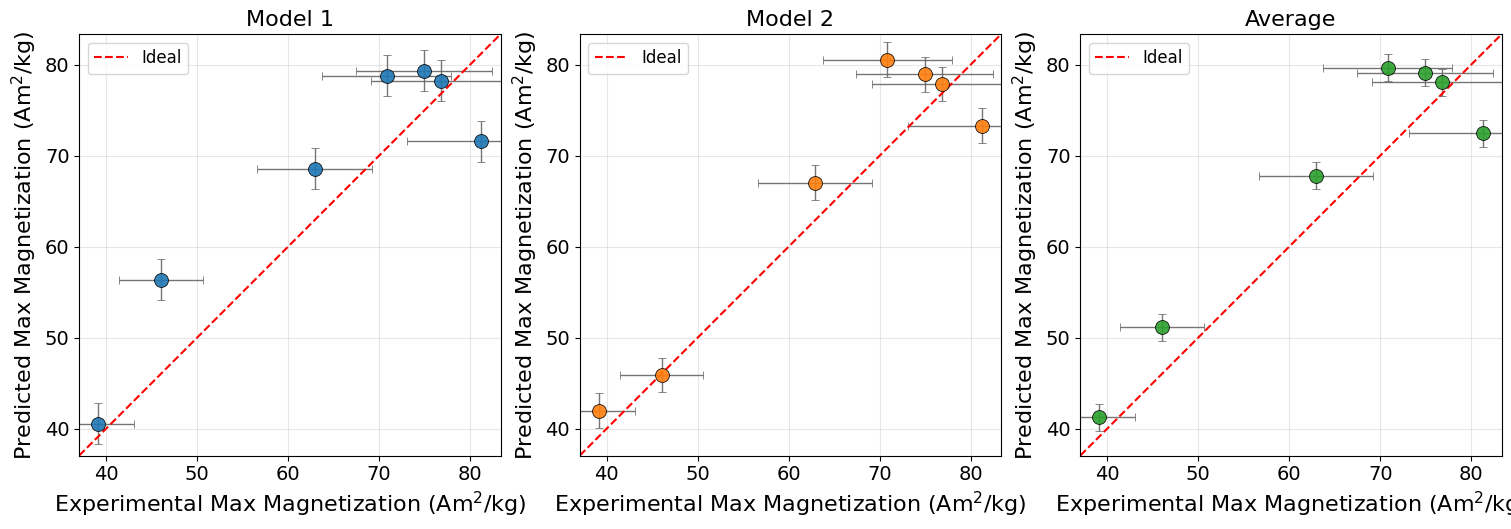

[rf_model_fe3o4_feo_dataset_N_1000_r_42_v2]  R^2=0.7968  MAE=5.83  RMSE=6.746  -> R2_MAE_RMSE_rf_model_fe3o4_feo_dataset_N_1000_r_42_v2.csv
[gb_model_fe3o4_feo_dataset_N_1000_r_42_v5]  R^2=0.8728  MAE=4.253  RMSE=5.337  -> R2_MAE_RMSE_gb_model_fe3o4_feo_dataset_N_1000_r_42_v5.csv


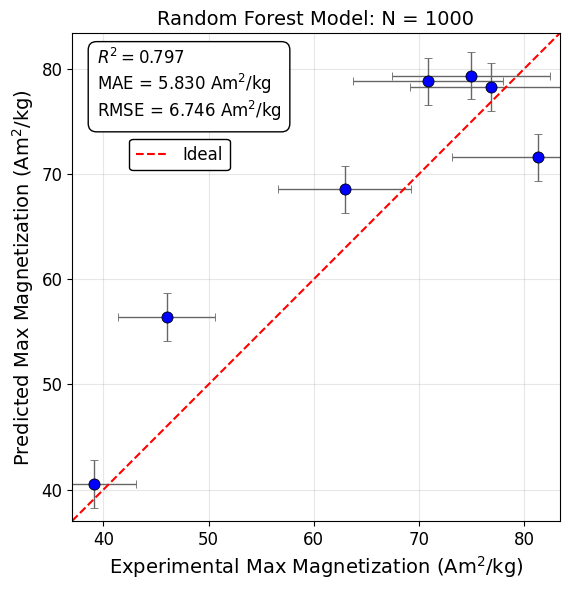

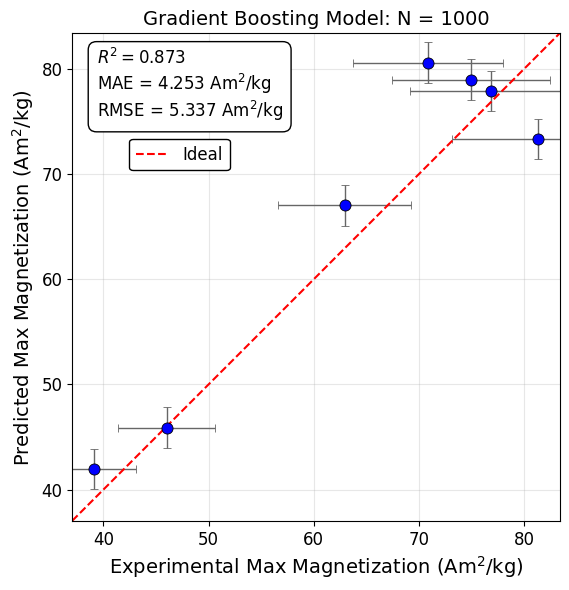

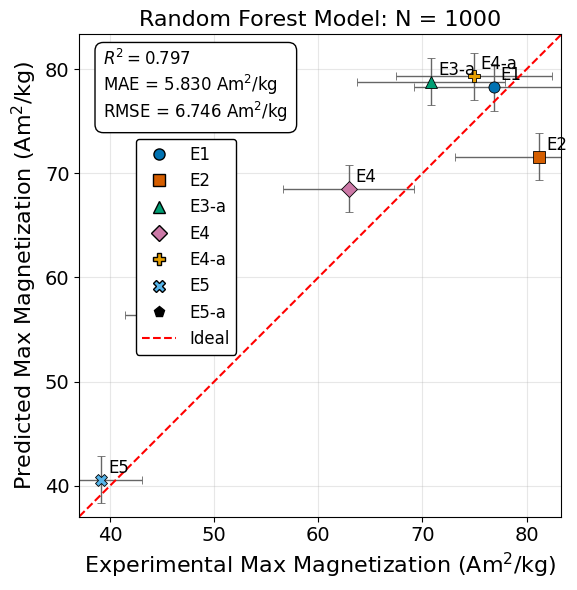

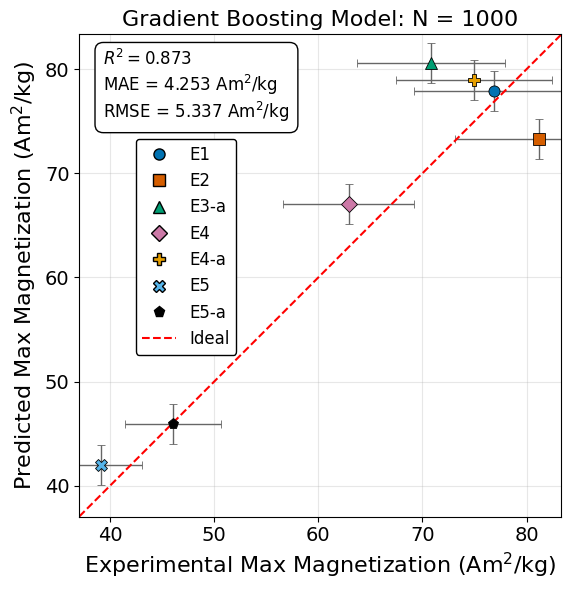

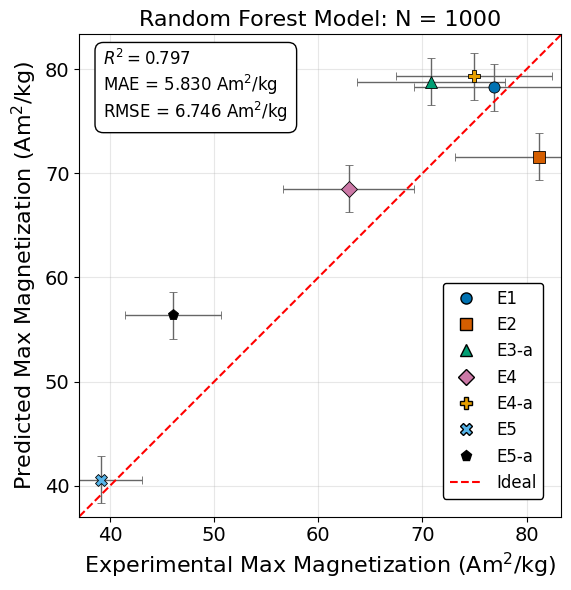

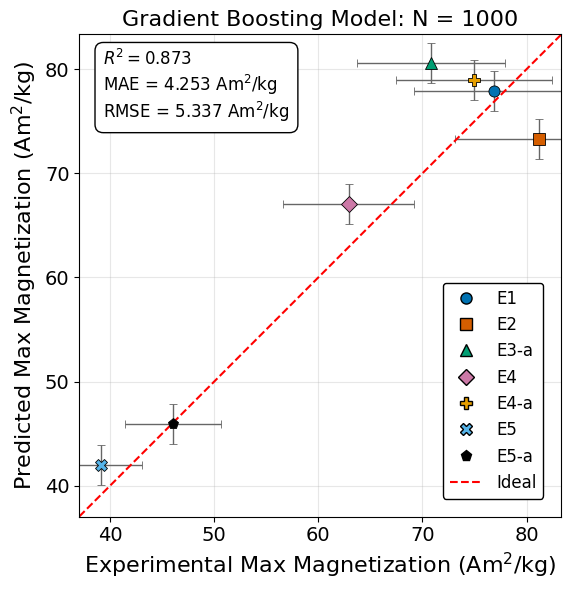

In [1]:
# Batch inference: XRD to predicted max magnetization, and compares to true max magnetization extracted from M-B measurements for each XRD
# updated directories

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from matplotlib.lines import Line2D 


# Inputs

# Paths
XRD_DIR = Path(r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Experimental_datasets") # folder containing XRD CSVs
MH_DIR  = Path(r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Experimental_datasets") # folder containing M-B CSVs
OUT_DIR = Path(r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Experimental_inference_output")
OUT_DIR_FIGS = Path(r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Saved_figures")


MODEL_DIR = Path(r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Trained_models")
DATA_DIR = Path(r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Simulated_datasets")

# Create the output directory if it does not exist
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Predicted y-error bars taken as RMSE or MAE on a held-out simulated set, units in (Am^2/kg)
PRED_RMSE_MODEL1 = 2.257 #rf RMSE for random seed 1/22/42/80 N = 1000 (sim. inference), changed for diff. max features
PRED_RMSE_MODEL2 = 1.922 #gb RMSE for random seed 1/22/42/80 N = 1000 (sim. inference)

# Estimate error in the measurement of magnetic mass used to calculated magnetization, taken as 10%, VersaLab error calibrated to be < 1%
MASS_REL_ERR    = 0.10   

# File lists 1:1 correspondance, XRD files and magnetization measurements 
# updated file names to better reflect convention used in the paper

XRD_FILES = [
    r"E1_XRD_20520_bg_sub.csv",
    r"E2_XRD_20520_bg_sub.csv",
    #r"E3_XRD_20520_bg_sub.csv",
    r"E3-aged_XRD_20520_bg_sub.csv",
    #r"E4_XRD_20520_bg_sub.csv",
    r"E4_XRD_20520_bg_sub_raw_2theta_shift_p0p193625deg.csv", #Bruker Processed
    r"E4-aged_XRD_20520_bg_sub.csv",
    r"E5_XRD_20520_bg_sub.csv",
    r"E5-aged_XRD_20520_bg_sub.csv",
]
MH_FILES = [
    r"E1_M-B.csv",
    r"E2_M-B.csv",
    #r"E3_M-B.csv",
    r"E3-aged_remade_M-B.csv",
    r"E4_M-B.csv",
    r"E4-aged_remade_M-B.csv",
    r"E5_M-B.csv",
    r"E5-aged_remade_M-B.csv",
]

# Masses in grams for each sample 1:1 correspondance with above files
MASSES_G = [  
    0.0015,
    0.0021,
    #0.0033,
    0.007, # measured was 0.0068 to 0.007, used 0.007 range recorded in orignal csv file
    0.0033,
    0.0050,
    0.0011,
    0.0253, # E5_S2, used in plots, updated in paper
]

# Models and grid sources from simulated training set
MODEL1_FILE  = r"rf_model_fe3o4_feo_dataset_N_1000_r_42_v2.pkl"
MODEL2_FILE  = r"gb_model_fe3o4_feo_dataset_N_1000_r_42_v5.pkl"
GRID_FILE = r"fe3o4_feo_dataset_N_1000_r_42.npz" # contains 2theta

MODEL1_PATH = MODEL_DIR / MODEL1_FILE
MODEL2_PATH = MODEL_DIR / MODEL2_FILE
GRID_SOURCE_PATH = DATA_DIR / GRID_FILE

# XRD processing params
CLIP_NONNEG    = True # Sets negative values to 0
CROP_TO_GRID   = True # crop raw data to training grid range
NORM_MODE      = "max"

# Loading M-B datafiles, specifcally for QD VersaLab when saved as a .csv
# magnetic field (Oe) starts in column D row 36, magnetic moment (emu) in column E row 36
MH_START_ROW = 35        # row 36 in Excel
MH_COL_FIELD = 3         # column D
MH_COL_MOM   = 4         # column E
USE_ABS_MAX  = False     # if True, uses max absolute value; else uses max(M) (there is minimal difference)

# Plot settings
DOT_SIZE = 45
FIGSIZE  = (15, 5)
FONTS    = dict(ax=16, tick=14, legend=12, title=16)

# Sample labels and colors for annotated scatter
#LEGEND_LABELS = ["E1", "E2", "E3", "E4", "E5", "E5-aged", "E3-aged"]
LEGEND_LABELS = ["E1", "E2","E3-a", "E4", "E4-a", "E5", "E5-a"]


# color options

COLORS_MB = [
    "#0072B2",  # blue
    "#D55E00",  # vermillion
    "#009E73",  # bluish green
    "#CC79A7",  # reddish purple
    "#E69F00",  # orange
    "#56B4E9",  # sky blue
    "#000000",  # black
]

#COLORS_MB = [
#    "#000000",  # black
#    "#FF0000",  # bright red
#    "#0000FF",  # bright blue
#    "#666666",  # dark gray
#    "#FF00FF",  # magenta
#    "#FF8C00",  # dark orange
#    "#00BFFF",  # bright cyan
#]

MARKERS = [
    "o",  # circle
    "s",  # square
    "^",  # upward triangle
    "D",  # diamond
    "P",  # filled plus
    "X",  # filled X
    "p",  # downward triangle
]

# Loading and csv reader functions
def load_two_theta_grid(grid_source_path):
    p = Path(grid_source_path)
    if p.suffix.lower() == ".npz":
        data = np.load(p, allow_pickle=True)
        if "two_theta" not in data:
            raise KeyError("NPZ missing 'two_theta'.")
        return np.asarray(data["two_theta"]).astype(float)
    elif p.suffix.lower() == ".npy":
        return np.load(p).astype(float)
    else:
        raise ValueError("GRID_SOURCE must be .npz (with 'two_theta') or .npy of the training grid.")

# Read XRD CSV with either named columns (2theta/intensity) or first two columns, cuts first row, but its vale is less than 25 degrees
#def smart_read_xrd_csv(path):
#    df = pd.read_csv(path)
#    cols = {c.lower(): c for c in df.columns}
#    th_keys = [k for k in cols if k in ["2theta", "two_theta", "angle", "2θ", "theta"]]
#    I_keys  = [k for k in cols if k in ["intensity", "counts", "i", "y"]]
#    if th_keys and I_keys:
#        x = df[cols[th_keys[0]]].to_numpy(dtype=float)
#        y = df[cols[I_keys[0]]].to_numpy(dtype=float)
#    else:
#        x = df.iloc[:, 0].to_numpy(dtype=float)
#        y = df.iloc[:, 1].to_numpy(dtype=float)
#    m = np.isfinite(x) & np.isfinite(y)
#    x, y = x[m], y[m]
#    order = np.argsort(x)
#    return x[order], y[order]

def smart_read_xrd_csv(path):
    """
    Read XRD data with or without a header.

    Recognized header examples:
      2theta, two_theta, angle, 2θ, theta
      intensity, counts, i, y

    If no recognized header exists, the first two columns are used and the
    first numeric data row is preserved.
    """
    df = pd.read_csv(path, header=None, dtype=str)

    if df.shape[1] < 2:
        raise ValueError("XRD file must contain at least two columns.")

    def normalize(value):
        return str(value).strip().lower().replace(" ", "_")

    first_row = [normalize(value) for value in df.iloc[0]]

    theta_names = {"2theta", "two_theta", "angle", "2θ", "theta"}
    intensity_names = {"intensity", "counts", "i", "y"}

    theta_columns = [
        index for index, name in enumerate(first_row)
        if name in theta_names
    ]
    intensity_columns = [
        index for index, name in enumerate(first_row)
        if name in intensity_names
    ]

    if theta_columns and intensity_columns:
        # A recognized header is present, so exclude it.
        data = df.iloc[1:]
        x_column = theta_columns[0]
        y_column = intensity_columns[0]
    else:
        # No recognized header: preserve the first row of data.
        data = df
        x_column = 0
        y_column = 1

    # Textual or malformed rows become NaN and are removed below.
    x = pd.to_numeric(data.iloc[:, x_column], errors="coerce").to_numpy()
    y = pd.to_numeric(data.iloc[:, y_column], errors="coerce").to_numpy()

    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]

    order = np.argsort(x)
    return x[order], y[order]

# Linear interpolation
def resample_to_grid(x, y, grid, fill_value=0.0):
    y_grid = np.interp(grid, x, y, left=np.nan, right=np.nan)
    y_grid[grid < x.min()] = fill_value
    y_grid[grid > x.max()] = fill_value
    return np.nan_to_num(y_grid, nan=fill_value, posinf=fill_value, neginf=fill_value)

def normalize_max(y, eps=1e-12):
    y = np.asarray(y, float)
    m = np.nanmax(y)
    return y / (m if m > eps else eps)

# Loads model file
def load_model(path):
    import joblib, gzip, bz2, lzma, pickle as _p
    p = Path(path)
    try:
        return joblib.load(p)
    except Exception:
        pass
    try:
        with open(p, "rb") as f:
            return _p.load(f)
    except Exception:
        pass
    for opener in (gzip.open, bz2.open, lzma.open):
        try:
            with opener(p, "rb") as f:
                return _p.load(f)
        except Exception:
            continue
    with open(p, "rb") as f:
        head = f.read(8)
    raise RuntimeError(f"Could not load model {p}. Header: {head!r}")

#Preprocessing:
# True/False, crop to training grid range
# True/False, clip negatives
# Normalize to max = 1
# Resample to the training grid
# Normalize again to max = 1 (post-interp normalization)
    
def process_xrd_for_prediction_simple(x_path, grid, *,
                                      clip_nonneg=CLIP_NONNEG, 
                                      crop_to_grid=CROP_TO_GRID):
    
    x_raw, y_raw = smart_read_xrd_csv(x_path)
    grid_min, grid_max = float(np.min(grid)), float(np.max(grid))

    if crop_to_grid:
        m = (x_raw >= grid_min) & (x_raw <= grid_max)
        x_use, y_use = x_raw[m], y_raw[m]
        if x_use.size < 7:
            raise ValueError(f"{x_path}: too few points in training grid range.")
    else:
        x_use, y_use = x_raw, y_raw

    if clip_nonneg:
        y_use = np.clip(y_use, 0, None)

    # Normalize by max value on the raw axis
    y_norm = normalize_max(y_use)

    # Resample to training grid
    y_grid = resample_to_grid(x_use, y_norm, grid, fill_value=0.0)

    # Normalize again on the training grid (post-interp)
    y_grid = normalize_max(y_grid)

    return y_grid

def load_mh_csv(path, mass_g,
                start_row=MH_START_ROW, col_field=MH_COL_FIELD, col_moment=MH_COL_MOM,
                use_abs_max=USE_ABS_MAX):
    df = pd.read_csv(path, header=None)
    sub = df.iloc[start_row:, [col_field, col_moment]].copy()
    sub.columns = ["H_Oe", "m_emu"]
    H_T = sub["H_Oe"].to_numpy(dtype=float) * 1e-4
    # emu/g to Am$^2$/kg: numerically identical after dividing by grams
    M_Am2_per_kg = (sub["m_emu"].to_numpy(dtype=float) / float(mass_g))
    if use_abs_max:
        M_true = float(np.nanmax(np.abs(M_Am2_per_kg))) 
    else:
        M_true = float(np.nanmax(M_Am2_per_kg))
    return H_T, M_Am2_per_kg, M_true

# Inferance 
assert len(XRD_FILES) == len(MH_FILES) == len(MASSES_G), "Lists must have same length (N)."
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Load grid  and models
two_theta_grid = load_two_theta_grid(GRID_SOURCE_PATH)
assert isinstance(two_theta_grid, np.ndarray) and two_theta_grid.ndim == 1
model1 = load_model(MODEL1_PATH)
model2 = load_model(MODEL2_PATH)

# Process all samples
rows = []
for i, (xrd_name, mh_name, mass_g) in enumerate(zip(XRD_FILES, MH_FILES, MASSES_G), start=1):
    xrd_path = XRD_DIR / xrd_name
    mh_path  = MH_DIR / mh_name
    if not xrd_path.exists():
        raise FileNotFoundError(f"Missing XRD file: {xrd_path}")
    if not mh_path.exists():
        raise FileNotFoundError(f"Missing M-H file: {mh_path}")

    # Experimental magnetization from M-H
    _, _, M_true = load_mh_csv(mh_path, mass_g)

    # XRD to feature vector
    y_grid = process_xrd_for_prediction_simple(xrd_path, two_theta_grid)

    # Predict
    X_feat = y_grid.reshape(1, -1)
    #pred1 = float(np.ravel(model1.predict(X_feat))[0]) # orignal code
    #pred2 = float(np.ravel(model2.predict(X_feat))[0]) # orignal code
    pred1 = float(model1.predict(X_feat)[0])
    pred2 = float(model2.predict(X_feat)[0])
    pred_avg = 0.5 * (pred1 + pred2)

    rows.append({
        "sample": Path(xrd_name).stem,
        "xrd_file": str(xrd_path),
        "mh_file": str(mh_path),
        "mass_g": float(mass_g),
        "true_max_M_Am2_per_kg": M_true,
        "pred_RF": pred1,
        "pred_GB": pred2,
        "pred_avg": pred_avg,
    })
    print(f"[{i}/{len(XRD_FILES)}] {xrd_name}: true={M_true:.4g}, RF={pred1:.4g}, GB={pred2:.4g}, avg={pred_avg:.4g}")

results = pd.DataFrame(rows)
results_path = OUT_DIR / "predicted_vs_true_maxM.csv"
results.to_csv(results_path, index=False)
print(f"\nSaved results: {results_path.resolve()}")

# x and y error arrays
y_true = results["true_max_M_Am2_per_kg"].to_numpy()
# x error from mass uncertainty
xerr_all = MASS_REL_ERR * y_true

# error in predictions for each model
yerr_rf  = np.full_like(y_true, float(PRED_RMSE_MODEL1), dtype=float)
yerr_gb  = np.full_like(y_true, float(PRED_RMSE_MODEL2), dtype=float)

# average model y-error, combination of the two MAEs/RMSEs
yerr_avg = np.full_like(y_true, 0.5 * np.sqrt(PRED_RMSE_MODEL1**2 + PRED_RMSE_MODEL2**2), dtype=float)

# Plots
def _scatter_pred_vs_true(ax, y_true, y_pred, title, c="blue", xerr=None, yerr=None):
    # Error bars
    ax.errorbar(
        y_true, y_pred, xerr=xerr, yerr=yerr,
        fmt='o', ms=10, mfc=c, mec='k', mew=0.6,
        ecolor='0.4', elinewidth=1.0, capsize=3, alpha=0.9, label=None
    )
    # Ideal line
    lo = np.nanmin([y_true.min(), y_pred.min()])
    hi = np.nanmax([y_true.max(), y_pred.max()])
    pad = 0.05 * (hi - lo if hi > lo else 1.0)
    lo, hi = lo - pad, hi + pad
    ax.plot([lo, hi], [lo, hi], "r--", lw=1.5, label="Ideal")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Experimental Max Magnetization (Am$^2$/kg)", fontsize=FONTS["ax"])
    ax.set_ylabel("Predicted Max Magnetization (Am$^2$/kg)", fontsize=FONTS["ax"])
    ax.set_title(title, fontsize=FONTS["title"])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=FONTS["legend"])
    ax.tick_params(labelsize=FONTS["tick"])

fig, axes = plt.subplots(1, 3, figsize=FIGSIZE, constrained_layout=True)
_scatter_pred_vs_true(
    axes[0], y_true, results["pred_RF"].to_numpy(),  "Model 1",
    c="tab:blue", xerr=xerr_all, yerr=yerr_rf
)
_scatter_pred_vs_true(
    axes[1], y_true, results["pred_GB"].to_numpy(),  "Model 2",
    c="tab:orange", xerr=xerr_all, yerr=yerr_gb
)
_scatter_pred_vs_true(
    axes[2], y_true, results["pred_avg"].to_numpy(), "Average",
    c="tab:green", xerr=xerr_all, yerr=yerr_avg
)
#plt.savefig(OUT_DIR / "pred_vs_true_scatter.png", dpi=200)
plt.show()

# Metrics: R^2, MAE, RMSE for RF, GB, and Average; save per-model CSVs

def _rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def _save_metrics(y_true, y_pred, model_name, out_dir: Path):
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()
    assert y_true.shape == y_pred.shape and y_true.size > 0, "y_true/y_pred must match and be non-empty."

    R2   = r2_score(y_true, y_pred)
    MAE  = mean_absolute_error(y_true, y_pred)
    RMSE = _rmse(y_true, y_pred)

    dfm = pd.DataFrame({
        "model": [model_name],
        "n":     [int(y_true.size)],
        "R2":    [R2],
        "MAE":   [MAE],
        "RMSE":  [RMSE],
    })
    out_dir.mkdir(parents=True, exist_ok=True)
    csv_path = out_dir / f"R2_MAE_RMSE_{model_name}.csv"
    dfm.to_csv(csv_path, index=False)
    print(f"[{model_name}]  R^2={R2:.4f}  MAE={MAE:.4g}  RMSE={RMSE:.4g}  -> {csv_path.name}")

# Pull arrays from your results table
y_rf   = results["pred_RF"].to_numpy()
y_gb   = results["pred_GB"].to_numpy()
y_avg  = results["pred_avg"].to_numpy()

# Derive readable names from your .pkl paths
m1_name = MODEL1_PATH.stem
m2_name = MODEL2_PATH.stem

# Save metrics to CSV files
_save_metrics(y_true, y_rf,  m1_name, OUT_DIR)
_save_metrics(y_true, y_gb,  m2_name, OUT_DIR)

# Seperate plots for each model with metrics and error bars
def _metrics(y_true, y_pred):
    y_true = np.asarray(y_true, float).ravel()
    y_pred = np.asarray(y_pred, float).ravel()
    r2   = r2_score(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    return r2, mae, rmse

def plot_pred_vs_actual_single(y_true, y_pred, *, title, xerr=None, yerr=None, save_path=None):
    r2, mae, rmse = _metrics(y_true, y_pred)

    plt.figure(figsize=(6, 6))
    plt.errorbar(
        y_true, y_pred, xerr=xerr, yerr=yerr,
        fmt='o', ms=8, mfc='blue', mec='k', mew=0.6,
        ecolor='0.4', elinewidth=1.0, capsize=3, alpha=1.0
    )

    lo = min(np.nanmin(y_true), np.nanmin(y_pred))
    hi = max(np.nanmax(y_true), np.nanmax(y_pred))
    pad = 0.05 * (hi - lo if hi > lo else 1.0)
    lims = [lo - pad, hi + pad]

    plt.plot(lims, lims, 'r--', label='Ideal')
    plt.xlim(lims); plt.ylim(lims)
    plt.gca().set_aspect('equal', adjustable='box')

    plt.xlabel('Experimental Max Magnetization (Am$^2$/kg)', fontsize=14)
    plt.ylabel('Predicted Max Magnetization (Am$^2$/kg)', fontsize=14)
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    plt.title(title, fontsize=14)

    textstr = '\n'.join((
        f'$R^2 = {r2:.3f}$',
        f'MAE = {mae:.3f} Am$^2$/kg',
        f'RMSE = {rmse:.3f} Am$^2$/kg',
    ))
    plt.text(0.05, 0.97, textstr, transform=plt.gca().transAxes,
             fontsize=12, verticalalignment='top',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=1.0))

    legend = plt.legend(loc='upper left', bbox_to_anchor=(0.1, 0.8),
                        fontsize=12, frameon=True)
    frame = legend.get_frame()
    frame.set_facecolor('white')
    frame.set_edgecolor('black')
    frame.set_alpha(1.0)
    frame.set_linewidth(1.0)

    plt.grid(alpha=0.3)
    plt.tight_layout()
    if save_path is not None:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=200)
    plt.show()


def plot_pred_vs_actual_single_annotated(
    y_true,
    y_pred,
    *,
    sample_labels,
    colors,
    title,
    xerr=None,
    yerr=None,
    save_path=None,
    legend_loc='upper left',
    legend_bbox=(0.1, 0.8),
    annotate_points=True,
):
    y_true = np.asarray(y_true, float).ravel()
    y_pred = np.asarray(y_pred, float).ravel()
    assert y_true.shape == y_pred.shape
    assert len(sample_labels) == y_true.size
    assert len(colors) == y_true.size

    r2, mae, rmse = _metrics(y_true, y_pred)

    plt.figure(figsize=(6, 6))

    # Plot each point separately so we can control color, marker and annotation
    for i, (yt, yp) in enumerate(zip(y_true, y_pred)):
        xe = xerr[i] if xerr is not None else None
        ye = yerr[i] if yerr is not None else None

        marker = MARKERS[i % len(MARKERS)]

        plt.errorbar(
            yt, yp, xerr=xe, yerr=ye,
            fmt=marker, ms=8, mfc=colors[i], mec='k', mew=0.6,
            ecolor='0.4', elinewidth=1.0, capsize=3, alpha=1.0
        )

        # Annotate point with E1, E2, ...
        if annotate_points:
            plt.annotate(
                sample_labels[i],
                xy=(yt, yp),
                xytext=(5, 5),
                textcoords='offset points',
                fontsize=12
            )
    
    # Axis limits and ideal line
    lo = min(np.nanmin(y_true), np.nanmin(y_pred))
    hi = max(np.nanmax(y_true), np.nanmax(y_pred))
    pad = 0.05 * (hi - lo if hi > lo else 1.0)
    lims = [lo - pad, hi + pad]

    plt.plot(lims, lims, 'r--', label='Ideal')
    plt.xlim(lims); plt.ylim(lims)
    plt.gca().set_aspect('equal', adjustable='box')

    plt.xlabel('Experimental Max Magnetization (Am$^2$/kg)', fontsize=16)
    plt.ylabel('Predicted Max Magnetization (Am$^2$/kg)', fontsize=16)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.title(title, fontsize=16)

    # Metrics textbox
    textstr = '\n'.join((
        f'$R^2 = {r2:.3f}$',
        f'MAE = {mae:.3f} Am$^2$/kg',
        f'RMSE = {rmse:.3f} Am$^2$/kg',
    ))
    plt.text(0.05, 0.97, textstr, transform=plt.gca().transAxes,
             fontsize=12, verticalalignment='top',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=1.0))

    # Legend showing colors and markers
    handles = []
    for i, (lab, c) in enumerate(zip(sample_labels, colors)):
        marker = MARKERS[i % len(MARKERS)]
        handles.append(
            Line2D([], [], marker=marker, linestyle='None',
                   markerfacecolor=c, markeredgecolor='k',
                   markersize=8, label=lab)
        )
    ideal_handle = Line2D([], [], linestyle='--', color='r', label='Ideal')
    handles.append(ideal_handle)

    legend = plt.legend(
        handles=handles,
        loc=legend_loc,
        bbox_to_anchor=legend_bbox,
        fontsize=12,
        frameon=True
    )
    frame = legend.get_frame()
    frame.set_facecolor('white')
    frame.set_edgecolor('black')
    frame.set_alpha(1.0)
    frame.set_linewidth(1.0)

    plt.grid(alpha=0.3)
    plt.tight_layout()
    if save_path is not None:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=600, bbox_inches='tight')
    plt.show()


# Seperate plots of model 1 and model 2
plot_pred_vs_actual_single(
    y_true, y_rf,
    #title=f"{Path(MODEL1_PKL).stem}",
    title="Random Forest Model: N = 1000",
    #title="Random Forest Model: Raw Data",
    #title="Random Forest Model: E4 Shift",
    xerr=xerr_all, yerr=yerr_rf,
    #save_path=OUT_DIR / f"pred_vs_true_{Path(MODEL1_PKL).stem}.png"
)

plot_pred_vs_actual_single(
    y_true, y_gb,
    #title=f"{Path(MODEL2_PKL).stem}",
    title="Gradient Boosting Model: N = 1000",
    #title="Gradient Boosting Model: Raw Data",
    #title="Gradient Boosting Model: E4 Shift",
    xerr=xerr_all, yerr=yerr_gb,
    #save_path=OUT_DIR / f"pred_vs_true_{Path(MODEL2_PKL).stem}.png"
)

# Additional annotated plot: each point colored and labeled S1–S5
plot_pred_vs_actual_single_annotated(
    y_true,
    y_rf,  # or y_rf, or y_avg if you prefer
    sample_labels=LEGEND_LABELS,
    colors=COLORS_MB,
    #title="GB Model: Max Features = 0.3",
    title="Random Forest Model: N = 1000",
    #title="Random Forest Model: E4 Shift",
    #title="Random Forest Model: Raw Data",
    #title="Gradient Boosting Model: N = 1000",
    xerr=xerr_all,
    yerr=yerr_rf,
    #save_path=OUT_DIR / "pred_vs_true_rf_annotated_E1_E5.png"
)

# Additional annotated plot: each point colored and labeled
plot_pred_vs_actual_single_annotated(
    y_true,
    y_gb,  # or y_rf, or y_avg if you prefer
    sample_labels=LEGEND_LABELS,
    colors=COLORS_MB,
    #title="GB Model: Max Features = sqrt",
    #title="Random Forest Model: N = 1000 v3",
    title="Gradient Boosting Model: N = 1000",
    #title="Gradient Boosting Model: E4 Shift",
    #title="Gradient Boosting Model: Raw Data",
    xerr=xerr_all,
    yerr=yerr_gb,
    annotate_points= False
    #save_path=OUT_DIR / "pred_vs_true_gb_r_5_v3_annotated_E1_E5.png"
)

# Additional RF annotated plot with sample legend in bottom-right
plot_pred_vs_actual_single_annotated(
    y_true,
    y_rf,
    sample_labels=LEGEND_LABELS,
    colors=COLORS_MB,
    title="Random Forest Model: N = 1000",
    #title="Random Forest Model: Raw Data",
    #title="Random Forest Model: E4 Shift",
    #title= "GB Model: max_features = 0.3, N = 1000",
    xerr=xerr_all,
    yerr=yerr_rf,
    legend_loc='lower right',
    legend_bbox=(0.98, 0.02),
    annotate_points=False,
    save_path=OUT_DIR_FIGS / "pred_vs_true_rf.svg"
)

# Additional GB annotated plot with sample legend in bottom-right
plot_pred_vs_actual_single_annotated(
    y_true,
    y_gb,
    sample_labels=LEGEND_LABELS,
    colors=COLORS_MB,
    title="Gradient Boosting Model: N = 1000",
    #title="Gradient Boosting Model: Raw Data",
    #title="Gradient Boosting Model: E4 Shift",
    #title= "GB Model: max_features = sqrt, N = 1000",
    xerr=xerr_all,
    yerr=yerr_gb,
    legend_loc='lower right',
    legend_bbox=(0.98, 0.02),
    annotate_points=False,
    save_path=OUT_DIR_FIGS / "pred_vs_true_gb.svg"
)


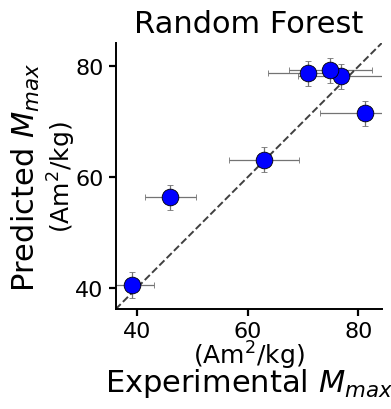

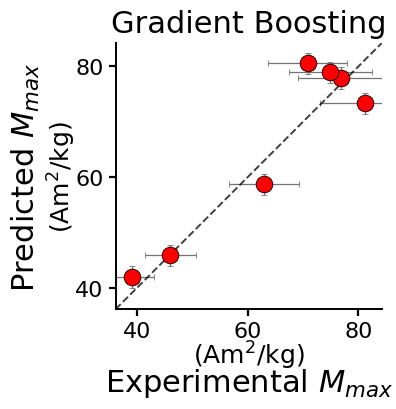

In [7]:

# plotting function and plots used for TOC, have to run main inference script first

OUT_DIR_FIGS = Path(r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Saved_figures")

def plot_pred_vs_actual_single_toc(
    y_true,
    y_pred,
    *,
    title,
    xerr=None,
    yerr=None,
    color="tab:blue",
    save_path=True
):
    """
    Minimal TOC-style predicted vs experimental plot.
    No legend, no grid, no metrics box, and no top/right box.
    """
    y_true = np.asarray(y_true, float).ravel()
    y_pred = np.asarray(y_pred, float).ravel()

    fig, ax = plt.subplots(figsize=(4.2, 4.2))

    ax.errorbar(
        y_true,
        y_pred,
        xerr=xerr,
        yerr=yerr,
        fmt="o",
        ms=12,
        mfc=color,
        mec="k",
        mew=0.6,
        ecolor="0.45",
        elinewidth=0.9,
        capsize=2.5,
        alpha=1.0
    )

    lo = min(np.nanmin(y_true), np.nanmin(y_pred))
    hi = max(np.nanmax(y_true), np.nanmax(y_pred))
    pad = 0.07 * (hi - lo if hi > lo else 1.0)
    lims = [lo - pad, hi + pad]

    ax.plot(lims, lims, linestyle="--", color="k", lw=1.4, alpha=0.75)

    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_aspect("equal", adjustable="box")


    # Force x-axis and y-axis to show the same tick labels
    toc_ticks = [40, 60, 80]
    ax.set_xticks(toc_ticks)
    ax.set_yticks(toc_ticks)

    #ax.set_xlabel("Experimental $M_{max}$\n(Am$^2$/kg)", fontsize=20)
    #ax.set_ylabel("Predicted $M_{max}$\n(Am$^2$/kg)", fontsize=20)
    # Larger axis names
    ax.set_xlabel("Experimental $M_{max}$", fontsize=22, labelpad=18)
    ax.set_ylabel("Predicted $M_{max}$", fontsize=22, labelpad=24)

        # Smaller unit labels
    ax.text(
        0.5, -0.11,
        "(Am$^2$/kg)",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=18
    )

    ax.text(
        -0.2, 0.5,
        "(Am$^2$/kg)",
        transform=ax.transAxes,
        ha="center",
        va="center",
        rotation=90,
        fontsize=18
    )


    
    ax.set_title(title, fontsize=22, pad=8)

    ax.tick_params(axis="both", labelsize=16, width=1.6, length=5)

    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.4)
    ax.spines["bottom"].set_linewidth(1.4)

    fig.tight_layout()

    if save_path is not None:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=2400, bbox_inches="tight", transparent=True)

    plt.show()

# TOC plots

plot_pred_vs_actual_single_toc(
    y_true,
    y_rf,
    title="Random Forest",
    xerr=xerr_all,
    yerr=yerr_rf,
    color="blue",
    save_path=OUT_DIR_FIGS / "TOC_random_forest_pred_vs_true.svg"
)

plot_pred_vs_actual_single_toc(
    y_true,
    y_gb,
    title="Gradient Boosting",
    xerr=xerr_all,
    yerr=yerr_gb,
    color="red",
    save_path=OUT_DIR_FIGS / "TOC_gradient_boosting_pred_vs_true.svg"
)

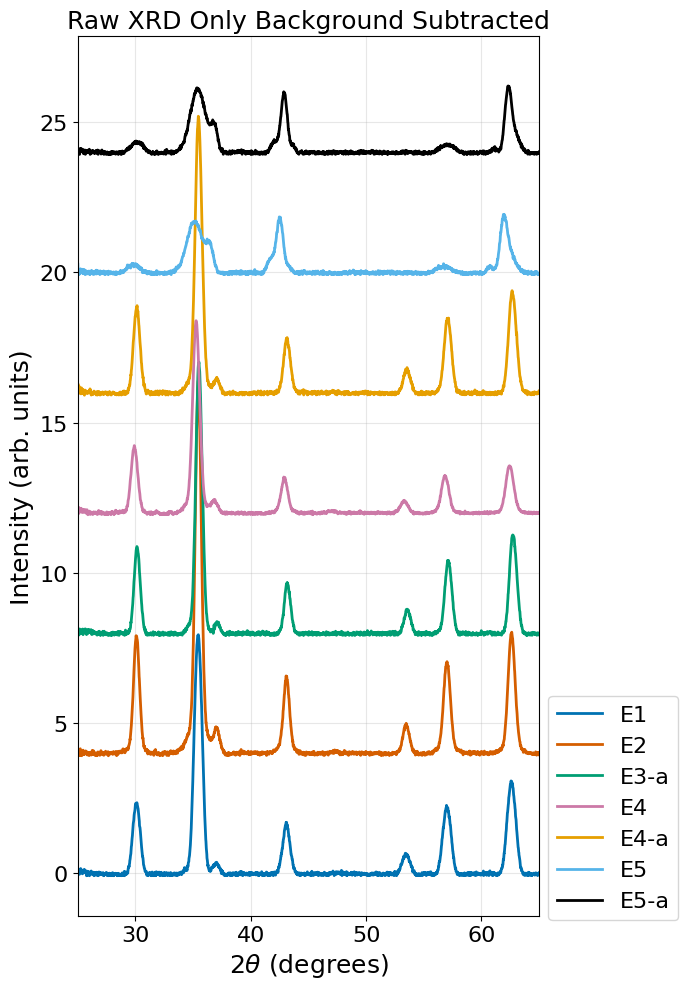

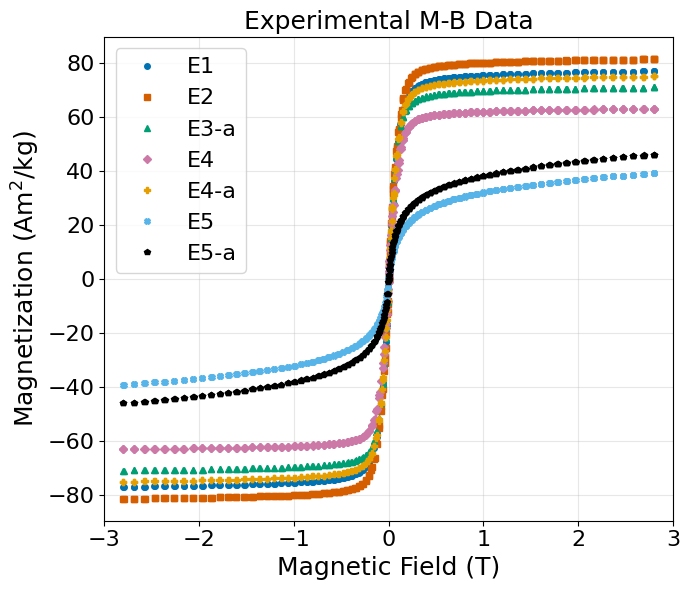

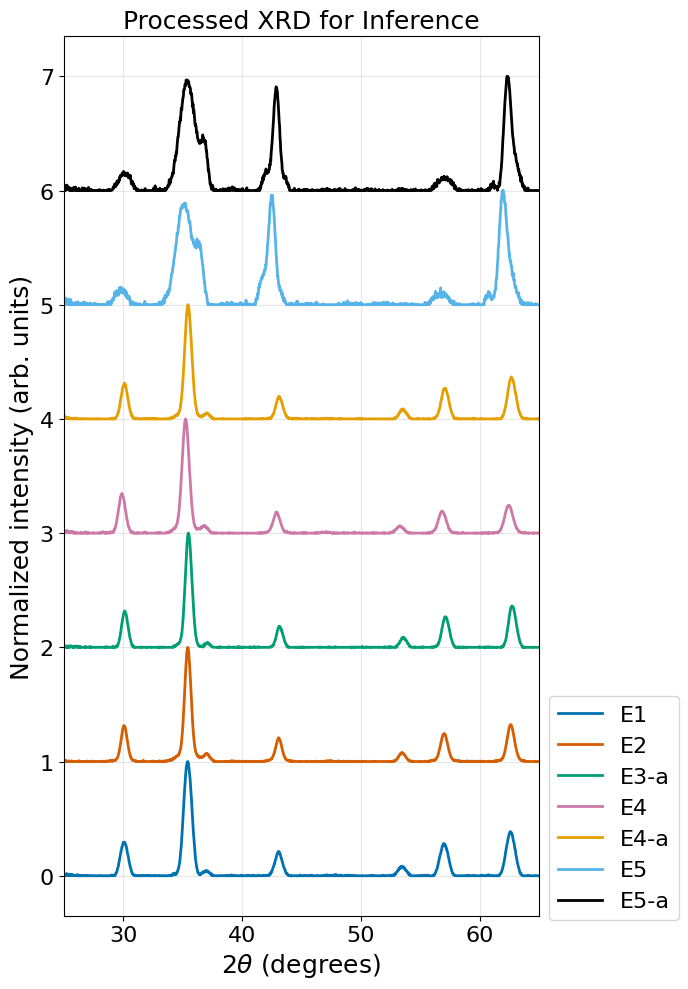

Saved XRD data to: C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Notebooks\raw_and_processed_xrd.csv
Exported 37,506 rows.


In [8]:
# Plot the exact experimental inputs used by the inference cell:

# Run this cell after the batch-inference cell.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUT_DIR_FIGS = Path(r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Saved_figures")
OUT_DIR_FIGS.mkdir(parents=True, exist_ok=True)


# Plot settings

RAW_XRD_Y_OFFSET = 4.0
PROCESSED_XRD_Y_OFFSET = 1.0

XRD_XLIM = (25, 65)
MB_XLIM = (-3, 3)

FIGSIZE_RAW_XRD = (7, 10)
FIGSIZE_MB = (7, 6)
FIGSIZE_PROCESSED_XRD = (7, 10)

FS_LABEL = 18
FS_TICK = 16
FS_TITLE = 18
FS_LEGEND = 16

LINEWIDTH_XRD = 2.0
MARKER_SIZE_MB = 4

# Confirm that the inference cell has already been run


_required_names = [
    "results",
    "LEGEND_LABELS",
    "COLORS_MB",
    "MARKERS",
    "two_theta_grid",
    "CLIP_NONNEG",
    "CROP_TO_GRID",
    "smart_read_xrd_csv",
    "process_xrd_for_prediction_simple",
    "load_mh_csv",
]

_missing_names = [
    name for name in _required_names
    if name not in globals()
]

if _missing_names:
    raise RuntimeError(
        "Run the complete batch-inference cell first. Missing:\n"
        + ", ".join(_missing_names)
    )

plot_n = len(results)

if plot_n == 0:
    raise RuntimeError("The inference results table is empty.")

assert len(LEGEND_LABELS) == plot_n, (
    f"Expected {plot_n} labels, but found {len(LEGEND_LABELS)}."
)
assert len(COLORS_MB) == plot_n, (
    f"Expected {plot_n} colors, but found {len(COLORS_MB)}."
)
assert len(MARKERS) == plot_n, (
    f"Expected {plot_n} markers, but found {len(MARKERS)}."
)

plot_labels = list(LEGEND_LABELS)
plot_colors = list(COLORS_MB)
plot_markers = list(MARKERS)

# Reload the exact files and masses recorded during inference

raw_xrd_series = []
processed_xrd_series = []
mass_normalized_mb_series = []

for row in results.itertuples(index=False):

    xrd_path = Path(row.xrd_file)
    mh_path = Path(row.mh_file)
    mass_g = float(row.mass_g)

    if not xrd_path.exists():
        raise FileNotFoundError(f"Missing XRD file: {xrd_path}")

    if not mh_path.exists():
        raise FileNotFoundError(f"Missing M-B file: {mh_path}")

    # Background-subtracted XRD before model preprocessing
    two_theta_raw, intensity_raw = smart_read_xrd_csv(xrd_path)
    raw_xrd_series.append(
        (two_theta_raw, intensity_raw)
    )

    # Exact preprocessing used during inference:
    intensity_processed = process_xrd_for_prediction_simple(
        xrd_path,
        two_theta_grid,
        clip_nonneg=CLIP_NONNEG,
        crop_to_grid=CROP_TO_GRID,
    )
    processed_xrd_series.append(
        intensity_processed
    )

    # Exact mass normalization used during inference
    field_T, magnetization_Am2kg, _ = load_mh_csv(
        mh_path,
        mass_g,
    )
    mass_normalized_mb_series.append(
        (field_T, magnetization_Am2kg)
    )

# Plot 1: XRD before model preprocessing, with y-offset

fig, ax = plt.subplots(figsize=FIGSIZE_RAW_XRD)

for i, ((two_theta_raw, intensity_raw), label) in enumerate(
    zip(raw_xrd_series, plot_labels)
):
    intensity_offset = (
        intensity_raw
        + i * RAW_XRD_Y_OFFSET
    )

    ax.plot(
        two_theta_raw,
        intensity_offset,
        color=plot_colors[i],
        lw=LINEWIDTH_XRD,
        label=label,
    )

ax.set_xlim(*XRD_XLIM)
ax.set_xlabel(r"2$\theta$ (degrees)", fontsize=FS_LABEL)
ax.set_ylabel(
    "Intensity (arb. units)",
    fontsize=FS_LABEL,
)
ax.set_title(
    "Raw XRD Only Background Subtracted",
    fontsize=FS_TITLE,
)
ax.tick_params(axis="both", labelsize=FS_TICK)
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 0.25),
    borderaxespad=0,
    fontsize=FS_LEGEND,
    frameon=True,
)

ax.grid(alpha=0.3)

fig.tight_layout()
# Plot 1
fig.savefig(
    OUT_DIR_FIGS / "raw_xrd_background_subtracted.svg",
    format="svg",
    bbox_inches="tight",
)
plt.show()

# Plot 2: experimental M-B data after mass normalization

fig, ax = plt.subplots(figsize=FIGSIZE_MB)

for i, ((field_T, magnetization_Am2kg), label) in enumerate(
    zip(mass_normalized_mb_series, plot_labels)
):
    ax.plot(
        field_T,
        magnetization_Am2kg,
        linestyle="none",
        marker=plot_markers[i],
        markersize=4,
        markerfacecolor=plot_colors[i],
        markeredgecolor=plot_colors[i],
        color=plot_colors[i],
        label=label,
    )

ax.set_xlim(*MB_XLIM)
ax.set_xlabel(
    "Magnetic Field (T)",
    fontsize=FS_LABEL,
)
ax.set_ylabel(
    "Magnetization (Am$^2$/kg)",
    fontsize=FS_LABEL,
)
ax.set_title(
    "Experimental M-B Data",
    fontsize=FS_TITLE,
)
ax.tick_params(
    axis="both",
    labelsize=FS_TICK,
)
ax.legend(
    fontsize=FS_LEGEND,
    frameon=True,
)
ax.grid(alpha=0.3)

fig.tight_layout()
# Plot 2
fig.savefig(
    OUT_DIR_FIGS / "experimental_mb_mass_normalized.svg",
    format="svg",
    bbox_inches="tight",
)
plt.show()

# Plot 3: XRD after preprocessing, with y-offset

fig, ax = plt.subplots(figsize=FIGSIZE_PROCESSED_XRD)

for i, (intensity_processed, label) in enumerate(
    zip(processed_xrd_series, plot_labels)
):
    intensity_offset = (
        intensity_processed
        + i * PROCESSED_XRD_Y_OFFSET
    )

    ax.plot(
        two_theta_grid,
        intensity_offset,
        color=plot_colors[i],
        lw=LINEWIDTH_XRD,
        label=label,
    )

ax.set_xlim(*XRD_XLIM)
ax.set_xlabel(r"2$\theta$ (degrees)", fontsize=FS_LABEL)
ax.set_ylabel(
    "Normalized intensity (arb. units)",
    fontsize=FS_LABEL,
)
ax.set_title(
    "Processed XRD for Inference",
    fontsize=FS_TITLE,
)
ax.tick_params(axis="both", labelsize=FS_TICK)
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 0.25),
    borderaxespad=0,
    fontsize=FS_LEGEND,
    frameon=True,
)
ax.grid(alpha=0.3)

fig.tight_layout()
# Plot 3
fig.savefig(
    OUT_DIR_FIGS / "processed_xrd_for_inference.svg",
    format="svg",
    bbox_inches="tight",
)
plt.show()

# Save raw and processed XRD data to one CSV

XRD_EXPORT_PATH = Path("./raw_and_processed_xrd.csv")

xrd_export_frames = []

for sample_index, (
    row,
    label,
    raw_data,
    intensity_processed,
) in enumerate(
    zip(
        results.itertuples(index=False),
        plot_labels,
        raw_xrd_series,
        processed_xrd_series,
    ),
    start=1,
):
    two_theta_raw, intensity_raw = raw_data

    two_theta_raw = np.asarray(two_theta_raw).reshape(-1)
    intensity_raw = np.asarray(intensity_raw).reshape(-1)
    processed_x = np.asarray(two_theta_grid).reshape(-1)
    intensity_processed = np.asarray(
        intensity_processed
    ).reshape(-1)

    # Raw, background-subtracted XRD
    raw_df = pd.DataFrame({
        "sample_index": sample_index,
        "sample_label": label,
        "source_file": str(row.xrd_file),
        "data_stage": "raw_background_subtracted",
        "two_theta_deg": two_theta_raw,
        "intensity": intensity_raw,
    })

    # Processed XRD used as model input
    processed_df = pd.DataFrame({
        "sample_index": sample_index,
        "sample_label": label,
        "source_file": str(row.xrd_file),
        "data_stage": "processed_for_inference",
        "two_theta_deg": processed_x,
        "intensity": intensity_processed,
    })

    xrd_export_frames.extend([raw_df, processed_df])

xrd_export_df = pd.concat(
    xrd_export_frames,
    ignore_index=True,
)

xrd_export_df.to_csv(
    XRD_EXPORT_PATH,
    index=False,
)

print(f"Saved XRD data to: {XRD_EXPORT_PATH.resolve()}")
print(f"Exported {len(xrd_export_df):,} rows.")

In [ ]:
# Inference on a single XRD file to predict max magnetization of iron oxide nanoparticles
import numpy as np
import pandas as pd
from pathlib import Path

# User inputs

# XRD file 
XRD_DIR  = r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Experimental_datasets"       
XRD_FILE = r"E5-aged_XRD_20520.csv"        

# Model file 
MODEL_DIR  = r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Trained_models"  
#MODEL_FILE = r"rf_model_fe3o4_feo_dataset_N_1000_r_42_v2.pkl"
MODEL_FILE = r"gb_model_fe3o4_feo_dataset_N_1000_r_42_v5.pkl"            


#PRED_ERROR_VALUE = 1.656 # GB 42 V3 RMSE or MAE from prediction on heldout simulated data 
#PRED_ERROR_VALUE = 1.922 # GB 42 V5 RMSE or MAE from prediction on heldout simulated data 

PRED_ERROR_VALUE = 2.257 # RMSE or MAE from prediction on heldout simulated data 
PRED_ERROR_NAME  = "RMSE"     

# Preprocessing conditions
CLIP_NONNEG  = True # set negatives to zero
CROP_TO_GRID = True # crop XRD to training grid range before resampling

# Load CSV file, XRD CSV with either named columns (2theta/intensity) or first two columns

def smart_read_xrd_csv(path):
    """
    Read XRD data with or without a header.

    Recognized header examples:
      2theta, two_theta, angle, 2θ, theta
      intensity, counts, i, y

    If no recognized header exists, the first two columns are used and the
    first numeric data row is preserved.
    """
    df = pd.read_csv(path, header=None, dtype=str)

    if df.shape[1] < 2:
        raise ValueError("XRD file must contain at least two columns.")

    def normalize(value):
        return str(value).strip().lower().replace(" ", "_")

    first_row = [normalize(value) for value in df.iloc[0]]

    theta_names = {"2theta", "two_theta", "angle", "2θ", "theta"}
    intensity_names = {"intensity", "counts", "i", "y"}

    theta_columns = [
        index for index, name in enumerate(first_row)
        if name in theta_names
    ]
    intensity_columns = [
        index for index, name in enumerate(first_row)
        if name in intensity_names
    ]

    if theta_columns and intensity_columns:
        # A recognized header is present, so exclude it.
        data = df.iloc[1:]
        x_column = theta_columns[0]
        y_column = intensity_columns[0]
    else:
        # No recognized header: preserve the first row of data.
        data = df
        x_column = 0
        y_column = 1

    # Textual or malformed rows become NaN and are removed below.
    x = pd.to_numeric(data.iloc[:, x_column], errors="coerce").to_numpy()
    y = pd.to_numeric(data.iloc[:, y_column], errors="coerce").to_numpy()

    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]

    order = np.argsort(x)
    return x[order], y[order]

def resample_to_grid(x, y, grid, fill_value=0.0):
    y_grid = np.interp(grid, x, y, left=np.nan, right=np.nan)
    y_grid[grid < x.min()] = fill_value
    y_grid[grid > x.max()] = fill_value
    return np.nan_to_num(y_grid, nan=fill_value, posinf=fill_value, neginf=fill_value)

def normalize_max(y, eps=1e-12):
    y = np.asarray(y, float)
    m = np.nanmax(y)
    return y / (m if m > eps else eps)

# Model loader
def load_model(path):
    import joblib, gzip, bz2, lzma, pickle as _p
    p = Path(path)
    try:
        return joblib.load(p)
    except Exception:
        pass
    try:
        with open(p, "rb") as f:
            return _p.load(f)
    except Exception:
        pass
    for opener in (gzip.open, bz2.open, lzma.open):
        try:
            with opener(p, "rb") as f:
                return _p.load(f)
        except Exception:
            continue
    with open(p, "rb") as f:
        head = f.read(8)
    raise RuntimeError(f"Could not load model {p}. Header: {head!r}")

#Preprocessing:
# True/False, crop to training grid range
# True/False, clip negatives
# Normalize to max = 1
# Resample to the training grid
# Normalize again to max = 1 (post-interp normalization)
def process_xrd_for_prediction_simple(x_path, grid, *,
                                      clip_nonneg=CLIP_NONNEG,
                                      crop_to_grid=CROP_TO_GRID):
    x_raw, y_raw = smart_read_xrd_csv(x_path)
    grid_min, grid_max = float(np.min(grid)), float(np.max(grid))

    if crop_to_grid:
        m = (x_raw >= grid_min) & (x_raw <= grid_max)
        x_use, y_use = x_raw[m], y_raw[m]
        if x_use.size < 7:
            raise ValueError(f"{x_path}: too few points in training grid range.")
    else:
        x_use, y_use = x_raw, y_raw

    if clip_nonneg:
        y_use = np.clip(y_use, 0, None)

    y_norm = normalize_max(y_use)
    y_grid = resample_to_grid(x_use, y_norm, grid, fill_value=0.0)
    y_grid = normalize_max(y_grid)
    return y_grid

# Main prediction function
def main():
    xrd_path   = Path(XRD_DIR)   / XRD_FILE
    model_path = Path(MODEL_DIR) / MODEL_FILE

    if not xrd_path.exists():
        raise FileNotFoundError(f"Missing XRD file: {xrd_path}")
    if not model_path.exists():
        raise FileNotFoundError(f"Missing model file: {model_path}")

    two_theta_grid = np.linspace(25.0, 65.0, 2000)

    model = load_model(model_path)

    n_in = getattr(model, "n_features_in_", None)
    if n_in is not None and int(n_in) != two_theta_grid.size:
        raise RuntimeError(
            f"Model expects n_features_in_={n_in}, but grid has {two_theta_grid.size} points. "
            "Confirm the fixed grid matches what the model was trained on."
        )

    # XRD t0 feature vector
    y_grid = process_xrd_for_prediction_simple(xrd_path, two_theta_grid)

    # Predict
    X_feat = y_grid.reshape(1, -1)   # shape (1, n_features)
    pred   = float(np.ravel(model.predict(X_feat))[0])

    # Print result with provided uncertainty
    print("==============================================")
    print("XRD inference")
    print("----------------------------------------------")
    print(f"XRD file : {xrd_path.name}  (dir: {xrd_path.parent})")
    print(f"Model    : {model_path.name}  (dir: {model_path.parent})")
    print("----------------------------------------------")
    print(f"Predicted max magnetization: {pred:.4g} Am^2/kg")
    print(f"Reported uncertainty      : ±{PRED_ERROR_VALUE:.4g} Am^2/kg ({PRED_ERROR_NAME})")
    print("==============================================")

if __name__ == "__main__":
    main()


In [ ]:
# Double-y plot N vs. R^2, MAE, RMSE

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Inputs
CSV_PATH   = Path(r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Experimental_inference_output/R2_MAE_RMSE_gb_model_fe3o4_feo_dataset_N_all_r_42_v5_7_samples_no_E3.csv")
#TITLE      = "RF Model max_features = 0.3: Metrics for Experimental Data"
#TITLE      = "RF Model max_features = sqrt: Metrics for Experimental Data"

#TITLE      = "GB Model max_features = 0.3: Metrics for Experimental Data"
TITLE      = "GB Model max_features = sqrt: Metrics for Experimental Data"


FONTS      = dict(ax=20, tick=16, legend=16, title=18)
SAVE_PNG   = False
OUT_PATH   = Path("./r2_mae_rmse_double_y.png")

# Legend location
LEGEND_LOC = "center right"
LEGEND_ANCHOR = (1.0, 0.62)

# Colors for datapoints/lines
COLOR_R2   = "black"
COLOR_MAE  = "blue"  
COLOR_RMSE = "red"

# Load CSV
df = pd.read_csv(CSV_PATH)  # Add sep="\t" if tab-separated
df.columns = df.columns.str.strip()

required_columns = ["N", "R2", "MAE", "RMSE"]
missing = [column for column in required_columns if column not in df.columns]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}. "
        f"Found columns: {df.columns.tolist()}"
    )

# Convert invalid values to NaN
df[required_columns] = df[required_columns].apply(
    pd.to_numeric, errors="coerce"
)

# Remove NaN and infinite values, then sort by N
df = (
    df.replace([np.inf, -np.inf], np.nan)
      .dropna(subset=required_columns)
      .sort_values("N")
)

x = df["N"].to_numpy()
R2 = df["R2"].to_numpy()
MAE = df["MAE"].to_numpy()
RMSE = df["RMSE"].to_numpy()

# Plot
fig, ax_left = plt.subplots(figsize=(10, 6))

# Left y-axis: R^2
line_r2, = ax_left.plot(
    x, R2, '-o', lw=2, ms=10,
    color=COLOR_R2, markerfacecolor=COLOR_R2, markeredgecolor='k',
    label=r"$R^2$"
)
ax_left.set_xlabel("Dataset Size, N", fontsize=FONTS["ax"])
ax_left.set_ylabel(r"$R^2$", fontsize=FONTS["ax"])
ax_left.tick_params(axis='both', labelsize=FONTS["tick"])
ax_left.grid(alpha=0.3)

# Right y-axis: MAE and RMSE
ax_right = ax_left.twinx()
line_mae,  = ax_right.plot(
    x, MAE, '--s', lw=2, ms=10,
    color=COLOR_MAE, markerfacecolor=COLOR_MAE, markeredgecolor='k',
    label="MAE"
)
line_rmse, = ax_right.plot(
    x, RMSE, '-.^', lw=2, ms=10,
    color=COLOR_RMSE, markerfacecolor=COLOR_RMSE, markeredgecolor='k',
    label="RMSE"
)
ax_right.set_ylabel("Error, MAE / RMSE", fontsize=FONTS["ax"])
ax_right.tick_params(axis='y', labelsize=FONTS["tick"])

ax_left.set_title(TITLE, fontsize=FONTS["title"])

# Combined legend
lines  = [line_r2, line_mae, line_rmse]
labels = [l.get_label() for l in lines]
ax_left.legend(
    lines,
    labels,
    fontsize=FONTS["legend"],
    loc=LEGEND_LOC,
    bbox_to_anchor=LEGEND_ANCHOR,
    framealpha=0.9
)

plt.tight_layout()
if SAVE_PNG:
    fig.savefig(OUT_PATH, dpi=200)
plt.show()


Plotting E1: 241 measured points and 300 predicted points
Saved figure: C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Saved_figures\01_E1_rf_MB_from_XRD_1000_r_42_v2.pkl.svg


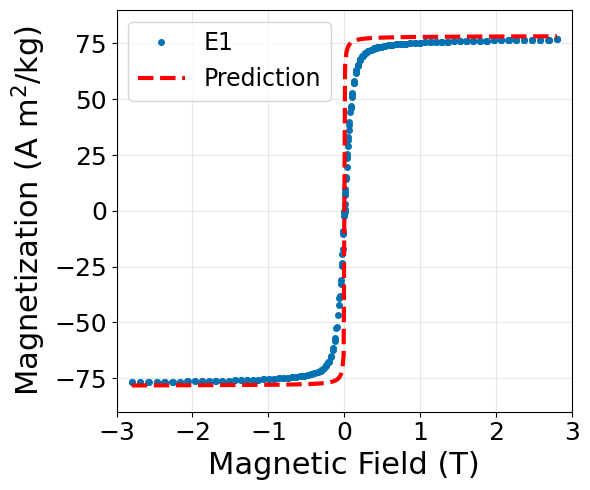

Plotting E2: 243 measured points and 300 predicted points
Saved figure: C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Saved_figures\02_E2_rf_MB_from_XRD_1000_r_42_v2.pkl.svg


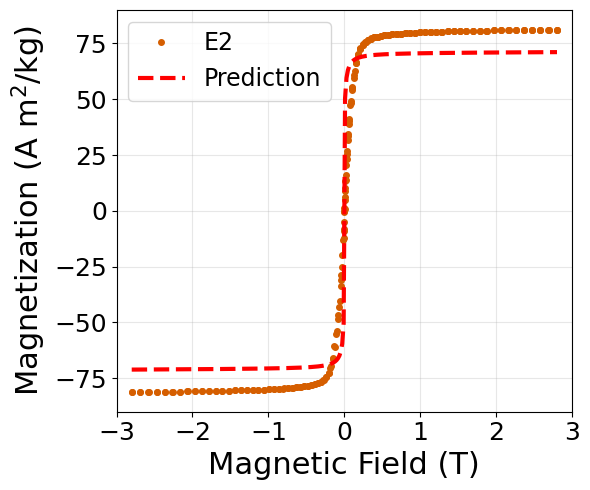

Plotting E3-a: 240 measured points and 300 predicted points
Saved figure: C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Saved_figures\03_E3-a_rf_MB_from_XRD_1000_r_42_v2.pkl.svg


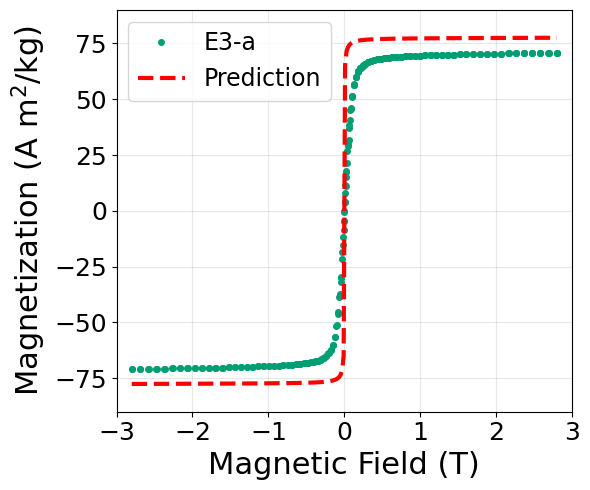

Plotting E4: 244 measured points and 300 predicted points
Saved figure: C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Saved_figures\04_E4_rf_MB_from_XRD_1000_r_42_v2.pkl.svg


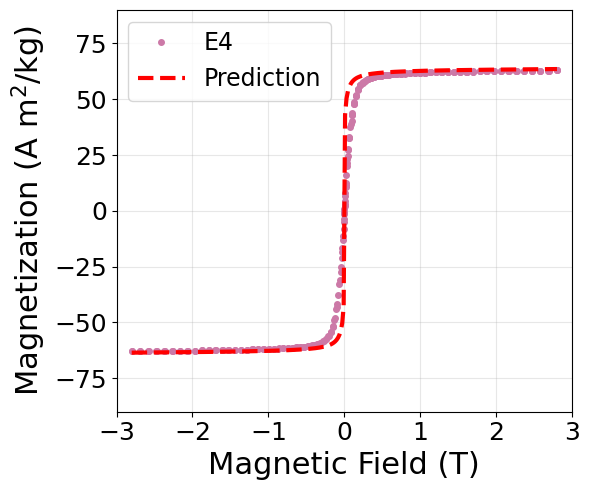

Plotting E4-a: 241 measured points and 300 predicted points
Saved figure: C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Saved_figures\05_E4-a_rf_MB_from_XRD_1000_r_42_v2.pkl.svg


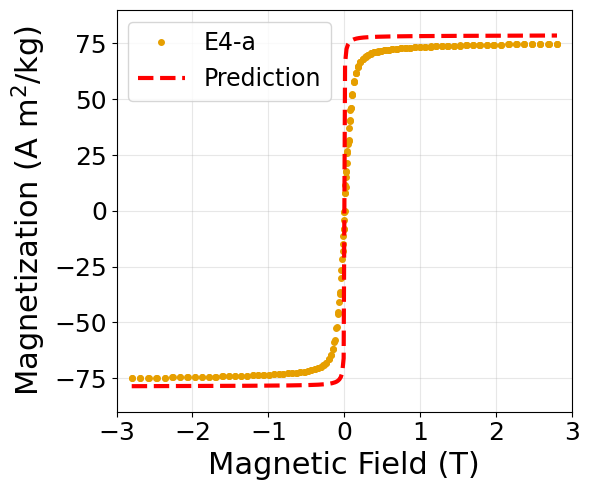

Plotting E5: 242 measured points and 300 predicted points
Saved figure: C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Saved_figures\06_E5_rf_MB_from_XRD_1000_r_42_v2.pkl.svg


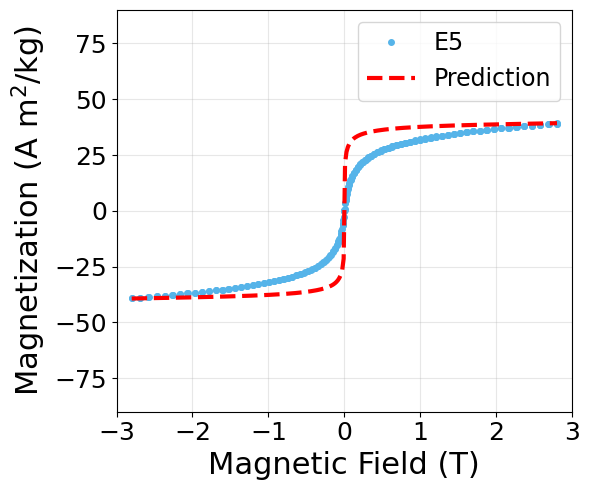

Plotting E5-a: 240 measured points and 300 predicted points
Saved figure: C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Saved_figures\07_E5-a_rf_MB_from_XRD_1000_r_42_v2.pkl.svg


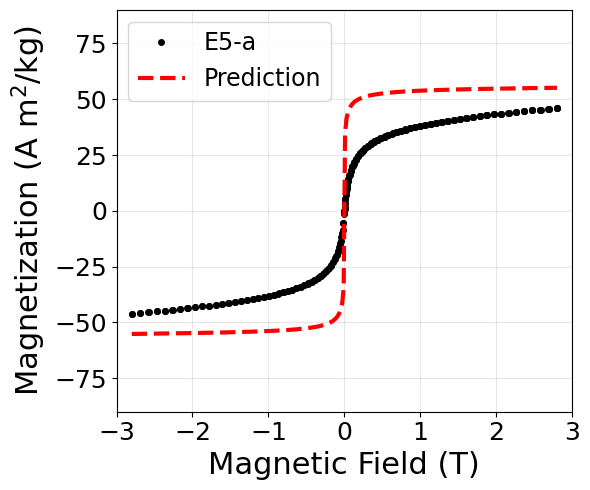

In [4]:
# Random Forest: XRD to full M-B curve model, inference of experimental data
# updated directories and code review
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

# Paths
XRD_DIR = Path(r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Experimental_datasets") # folder containing XRD CSVs
MH_DIR  = Path(r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Experimental_datasets") # folder containing M-B CSVs
OUT_DIR = Path(r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Experimental_inference_output")

MODEL_DIR = Path(r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Trained_models")
DATA_DIR = Path(r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Simulated_datasets")

OUT_DIR_FIGS = Path(r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Saved_figures")


# Create the output directory if it does not exist
OUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR_FIGS.mkdir(parents=True, exist_ok=True)

# File lists 1:1 correspondance, XRD files and magnetization measurements 


XRD_FILES = [
    r"E1_XRD_20520_bg_sub.csv",
    r"E2_XRD_20520_bg_sub.csv",
    #r"E3_XRD_20520_bg_sub.csv",
    r"E3-aged_XRD_20520_bg_sub.csv",
    r"E4_XRD_20520_bg_sub.csv",
    #r"E4_XRD_20520_bg_sub_raw_2theta_shift_p0p193625deg.csv", #Bruker Processed
    r"E4-aged_XRD_20520_bg_sub.csv",
    r"E5_XRD_20520_bg_sub.csv",
    r"E5-aged_XRD_20520_bg_sub.csv",
]
MH_FILES = [
    r"E1_M-B.csv",
    r"E2_M-B.csv",
    #r"E3_M-B.csv",
    r"E3-aged_remade_M-B.csv",
    r"E4_M-B.csv",
    r"E4-aged_remade_M-B.csv",
    r"E5_M-B.csv",
    r"E5-aged_remade_M-B.csv",
]

# Masses in grams for each sample 1:1 correspondance with above files
MASSES_G = [  
    0.0015,
    0.0021,
    #0.0033,
    0.007, # measured was 0.0068 to 0.007, used 0.007 range recorded in orignal csv file
    0.0033,
    0.0050,
    0.0011,
    0.0253, # E5_S2, used in plots, updated in paper
]


SAMPLE_LABELS = [
    "E1",
    "E2",
    "E3-a",
    "E4",
    "E4-a",
    "E5",
    "E5-a",
]

COLORS_MH = [
    "#0072B2",  # blue
    "#D55E00",  # vermillion
    "#009E73",  # bluish green
    "#CC79A7",  # reddish purple
    "#E69F00",  # orange
    "#56B4E9",  # sky blue
    "#000000",  # black
]


# Multi-output model, metadata, and fallback training dataset

MODEL_MH_FILE   = Path(r"rf_MB_from_XRD_1000_r_42_v2.pkl") # two models used v1 and v2 corresponding to 0.3 and sqrt max_features

MODEL_MH_PKL = MODEL_DIR / MODEL_MH_FILE
MODEL_META_NPZ = MODEL_MH_PKL.with_suffix(".meta.npz")

# XRD processing 
CLIP_NONNEG  = True
CROP_TO_GRID = True

GRID_FILE = Path(r"fe3o4_feo_dataset_N_1000_r_42.npz")  # contains 2theta grid

GRID_SOURCE_PATH = DATA_DIR / GRID_FILE

# VersaLab CSV format (for experimental M–H)
MH_START_ROW = 35  # zero-based (row 36 in Excel)
MH_COL_FIELD = 3   # column D (Oe)
MH_COL_MOM   = 4   # column E (emu)

# Plot style
FONTS = dict(ax=22, tick=18, legend=17, title=18)         

# Processing functions
def load_grids(meta_npz: Path, fallback_npz: Path):
    meta = np.load(meta_npz)
    if "B_field" not in meta:
        raise KeyError(f"{meta_npz} must contain 'B_field' for the prediction output grid.")
    B_field = np.asarray(meta["B_field"]).astype(float)
    if "two_theta" in meta:
        two_theta = np.asarray(meta["two_theta"]).astype(float)
    else:
        fb = np.load(fallback_npz, allow_pickle=True)
        if "two_theta" not in fb:
            raise KeyError(f"{fallback_npz} must contain 'two_theta' if meta lacks it.")
        two_theta = np.asarray(fb["two_theta"]).astype(float)
    return two_theta, B_field

def smart_read_xrd_csv(path):
    """
    Read an XRD CSV with either:
    1. A named header row, or
    2. Two numerical columns with no header.
    """
    # Read every row as data initially
    df = pd.read_csv(path, header=None)

    if df.shape[1] < 2:
        raise ValueError(
            f"{path}: expected at least two columns, found {df.shape[1]}."
        )

    def normalize_name(value):
        return (
            str(value)
            .strip()
            .lower()
            .replace(" ", "")
            .lstrip("\ufeff")
        )

    first_row = [normalize_name(value) for value in df.iloc[0]]


    theta_names = {
        "2theta",
        "two_theta",
        "angle",
        "2θ",
        "theta",
    }

    intensity_names = {
        "intensity",
        "counts",
        "i",
        "y",
    }

    theta_idx = next(
        (i for i, name in enumerate(first_row) if name in theta_names),
        None,
    )
    intensity_idx = next(
        (i for i, name in enumerate(first_row) if name in intensity_names),
        None,
    )

    if theta_idx is not None and intensity_idx is not None:
        # The first row is a recognized header
        data_start = 1
    else:
        # No recognized header: use the first two columns,
        # including the first row
        theta_idx = 0
        intensity_idx = 1
        data_start = 0

    x = pd.to_numeric(
        df.iloc[data_start:, theta_idx],
        errors="coerce",
    ).to_numpy(dtype=float)

    y = pd.to_numeric(
        df.iloc[data_start:, intensity_idx],
        errors="coerce",
    ).to_numpy(dtype=float)

    finite = np.isfinite(x) & np.isfinite(y)
    x = x[finite]
    y = y[finite]

    if x.size == 0:
        raise ValueError(f"{path}: no valid numerical XRD data found.")

    order = np.argsort(x)
    return x[order], y[order]

def normalize_max(y, eps=1e-12):
    y = np.asarray(y, float)
    m = np.nanmax(y)
    return y / (m if m > eps else eps)

def resample_to_grid(x, y, grid, fill_value=0.0):
    yg = np.interp(grid, x, y, left=np.nan, right=np.nan)
    yg[grid < x.min()] = fill_value
    yg[grid > x.max()] = fill_value
    return np.nan_to_num(yg, nan=fill_value, posinf=fill_value, neginf=fill_value)

# Preprocessing
def process_xrd_for_prediction_simple(x_path, grid, *, clip_nonneg=True, crop_to_grid=True):
    x_raw, y_raw = smart_read_xrd_csv(x_path)
    gmin, gmax = float(np.min(grid)), float(np.max(grid))
    if crop_to_grid:
        m = (x_raw >= gmin) & (x_raw <= gmax)
        x_use, y_use = x_raw[m], y_raw[m]
        if x_use.size < 7:
            raise ValueError(f"{x_path}: too few points within training grid range.")
    else:
        x_use, y_use = x_raw, y_raw
    if clip_nonneg:
        y_use = np.clip(y_use, 0, None)
    y_norm = normalize_max(y_use)
    y_grid = resample_to_grid(x_use, y_norm, grid, fill_value=0.0)
    y_grid = normalize_max(y_grid)
    return y_grid

# Load experimental M-B data
def load_mh_csv_full(path, mass_g, start_row=MH_START_ROW, col_field=MH_COL_FIELD, col_moment=MH_COL_MOM):
    df = pd.read_csv(path, header=None)
    sub = df.iloc[start_row:, [col_field, col_moment]].copy()
    sub.columns = ["H_Oe", "m_emu"]
    B_T = sub["H_Oe"].to_numpy(dtype=float) * 1e-4          # 1 Oe = 1e-4 T (in vacuum)
    M   = (sub["m_emu"].to_numpy(dtype=float) / float(mass_g))  # emu/g to Am^2/kg
    m = np.isfinite(B_T) & np.isfinite(M)
    return B_T[m], M[m]

def main():
    assert (
        len(XRD_FILES)
        == len(MH_FILES)
        == len(MASSES_G)
        == len(SAMPLE_LABELS)
        == len(COLORS_MH)
    ), "Experimental files, masses, labels, and colors must have equal lengths."

    if not MODEL_MH_PKL.exists():
        raise FileNotFoundError(
            f"Missing model file:\n{MODEL_MH_PKL}"
        )

    if not MODEL_META_NPZ.exists():
        raise FileNotFoundError(
            f"Missing model metadata:\n{MODEL_META_NPZ}"
        )

    if not GRID_SOURCE_PATH.exists():
        raise FileNotFoundError(
            f"Missing grid source dataset:\n{GRID_SOURCE_PATH}"
        )

    # Load the exact grids used during model training
    two_theta_grid, B_field = load_grids(
        MODEL_META_NPZ,
        GRID_SOURCE_PATH,
    )

    two_theta_grid = np.asarray(
        two_theta_grid,
        dtype=float,
    ).reshape(-1)

    B_field = np.asarray(
        B_field,
        dtype=float,
    ).reshape(-1)

    model = joblib.load(MODEL_MH_PKL)

    # Verify that the XRD grid matches the model input size
    if hasattr(model, "n_features_in_"):
        if model.n_features_in_ != two_theta_grid.size:
            raise ValueError(
                f"Model expects {model.n_features_in_} XRD features, "
                f"but the loaded grid has {two_theta_grid.size}."
            )

    # Process and plot every experimental sample
    for i, (xrd_name, mh_name, mass_g) in enumerate(
        zip(XRD_FILES, MH_FILES, MASSES_G)
    ):
        xrd_path = XRD_DIR / xrd_name
        mh_path = MH_DIR / mh_name

        if not xrd_path.exists():
            raise FileNotFoundError(
                f"Missing XRD file:\n{xrd_path}"
            )

        if not mh_path.exists():
            raise FileNotFoundError(
                f"Missing M-B file:\n{mh_path}"
            )

        # Process experimental XRD
        xrd_vec = process_xrd_for_prediction_simple(
            x_path=xrd_path,
            grid=two_theta_grid,
            clip_nonneg=CLIP_NONNEG,
            crop_to_grid=CROP_TO_GRID,
        )

        X_feat = xrd_vec.reshape(1, -1)

        # Predict the complete M-B curve
        prediction = np.asarray(
            model.predict(X_feat),
            dtype=float,
        )

        if prediction.shape[0] != 1:
            raise ValueError(
                f"Expected one prediction for {SAMPLE_LABELS[i]}, "
                f"but received shape {prediction.shape}."
            )

        M_pred = prediction[0].reshape(-1)

        if M_pred.size != B_field.size:
            raise ValueError(
                f"{SAMPLE_LABELS[i]}: prediction contains "
                f"{M_pred.size} points, but B_field contains "
                f"{B_field.size} points."
            )

        # Load raw experimental measurements and normalize by mass
        B_true, M_true = load_mh_csv_full(
            mh_path,
            mass_g,
        )

        label_true = SAMPLE_LABELS[i]

        print(
            f"Plotting {label_true}: "
            f"{B_true.size} measured points and "
            f"{M_pred.size} predicted points"
        )

        fig, ax = plt.subplots(figsize=(6, 5))

        # Every measured experimental point
        ax.plot(
            B_true,
            M_true,
            linestyle="none",
            marker="o",
            markersize=4,
            markerfacecolor=COLORS_MH[i],
            markeredgecolor=COLORS_MH[i],
            color=COLORS_MH[i],
            label=label_true,
        )

        # Predicted curve
        ax.plot(
            B_field,
            M_pred,
            color="r",
            linestyle="--",
            linewidth=3,
            label="Prediction",
        )

        ax.set_xlabel(
            "Magnetic Field (T)",
            fontsize=FONTS["ax"],
        )
        ax.set_ylabel(
            r"Magnetization (A m$^2$/kg)",
            fontsize=FONTS["ax"],
        )

        ax.set_xlim(-3, 3)
        ax.set_ylim(-90, 90)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=FONTS["legend"])
        ax.tick_params(labelsize=FONTS["tick"])

        fig.tight_layout()
                # Create a filesystem-safe, unique filename
        safe_label = "".join(
            char if char.isalnum() or char in "-_" else "_"
            for char in label_true
        ).strip("_")

        figure_path = (
            OUT_DIR_FIGS
            / f"{i + 1:02d}_{safe_label}_{MODEL_MH_FILE}.svg"
        )

        fig.savefig(
            figure_path,
            #dpi=600,
            bbox_inches="tight",
            facecolor="white",
        )

        print(f"Saved figure: {figure_path}")
        plt.show()
        plt.close(fig)

if __name__ == "__main__":
    main()

In [ ]:
# Plot time-series, this is just a plotting script, the single XRD inference script was just run on the experimental samples and the results were saved in a .csv file
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# User inputs
CSV_PATH     = Path(r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Experimental_inference_output\E5-aged_effect_of_XRD_time_and_bg_sub_GB_v5_model.csv")  # CSV with headers: time, data1, err1, data2, err2
#TITLE        = "Random Forest Model: max_features = sqrt, N = 1000"
TITLE        = "Gradient Boosting Model: max_features = 0.3, N = 1000"
X_LABEL      = "Time (s)"                         
Y_LABEL      = "Predicted Max Magnetization (Am$^2$/kg)"                    

PLOT_SERIES_2 = True                              

SERIES1_LABEL = "Without Background Subtraction"
SERIES2_LABEL = "With Background Subtraction"

TARGET_VALUE = 46.03                                # Experimental Value
BAND_FRAC    = 0.10                                # estimated error


LEGEND_LOC = "center right"
#LEGEND_ANCHOR = (0.98, 0.46)                       # e.g., "upper right", "center right", etc.
#LEGEND_ANCHOR = (0.5, 0.89)                       # used for E5-aged, RF

LEGEND_ANCHOR = (0.5, 0.89)                       # used for E5-aged, GB


SAVE_PNG     = False
OUT_PATH     = Path("./timeseries_with_banded_target.png")

FONTS = dict(ax=18, tick=16, legend=14, title=18)

# Colors/markers
COLOR_1 = "blue"
COLOR_2 = "red"
ECOLOR  = "0.4"          
MARKER_1 = "o"
MARKER_2 = "s"

# Load and parse CSV
df = pd.read_csv(CSV_PATH)

# Expecting columns: time, data1, err1, data2, err2 (with headers)
cols = list(df.columns)
if len(cols) < 3:
    raise ValueError("CSV must have at least 3 columns: time, data, error. Your file has fewer.")

x_col  = cols[0]
y1_col = cols[1]
e1_col = cols[2]
y2_col = cols[3] if len(cols) > 3 else None
e2_col = cols[4] if len(cols) > 4 else None

x  = df[x_col].to_numpy()
y1 = df[y1_col].to_numpy(dtype=float)
e1 = df[e1_col].to_numpy(dtype=float)

if PLOT_SERIES_2 and (y2_col is None or e2_col is None):
    raise ValueError("PLOT_SERIES_2=True, but the CSV does not have the 2nd data/error columns.")

y2 = df[y2_col].to_numpy(dtype=float) if (PLOT_SERIES_2 and y2_col) else None
e2 = df[e2_col].to_numpy(dtype=float) if (PLOT_SERIES_2 and e2_col) else None

m1 = np.isfinite(x) & np.isfinite(y1) & np.isfinite(e1)
if PLOT_SERIES_2:
    m2 = np.isfinite(x) & np.isfinite(y2) & np.isfinite(e2)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

# Series 1
ax.errorbar(
    x[m1], y1[m1],
    yerr=e1[m1],
    fmt=MARKER_1, ms=9, mfc=COLOR_1, mec='k', mew=0.6,
    ecolor=ECOLOR, elinewidth=1.0, capsize=3, alpha=0.95,
    ls='none', label=SERIES1_LABEL
)
# series 2
if PLOT_SERIES_2:
    ax.errorbar(
        x[m2], y2[m2],
        yerr=e2[m2],
        fmt=MARKER_2, ms=9, mfc=COLOR_2, mec='k', mew=0.6,
        ecolor=ECOLOR, elinewidth=1.0, capsize=3, alpha=0.95,
        ls='none', label=SERIES2_LABEL
    )

# Banded target line
y_lo = TARGET_VALUE * (1.0 - BAND_FRAC)
y_hi = TARGET_VALUE * (1.0 + BAND_FRAC)


ax.axhspan(
    y_lo,
    y_hi,
    color="tab:green",
    alpha=0.15,
    label="_nolegend_",
)

ax.axhline(
    TARGET_VALUE,
    color="tab:green",
    linewidth=2,
    linestyle="--",
    label=f"Measured: {TARGET_VALUE:.0f} ± {BAND_FRAC:.0%}",
)

# Labels, grid, legend, fonts
ax.set_xlabel(X_LABEL, fontsize=FONTS["ax"])
ax.set_ylabel(Y_LABEL, fontsize=FONTS["ax"])
ax.set_title(TITLE, fontsize=FONTS["title"])
ax.grid(alpha=0.3)
ax.tick_params(axis='both', labelsize=FONTS["tick"])
ax.set_xlim(0, 21000)
ax.legend(
    fontsize=FONTS["legend"],
    loc=LEGEND_LOC,
    bbox_to_anchor=LEGEND_ANCHOR,
    framealpha=0.9,
)


plt.tight_layout()
if SAVE_PNG:
    fig.savefig(OUT_PATH, dpi=200)
plt.show()


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# different plotting code used in the final version of the paper

# USER INPUTS

# File location
data_dir = r"C:\Users\fabel\Documents\materials-project\notesbooks\Iron_Oxide_Model\experimanta_data\XRD_M-B_datasets_manuscript_names"

# List of file names
file_list = [
    #"E2_XRD_205_bg_sub.csv",
    #"E2_XRD_2052_bg_sub.csv",
    #"E2_XRD_20520_bg_sub.csv",
    #"E5_260413_bg_sub_205.csv",
    #"E5_260413_bg_sub_2052.csv",
    #"E5_260413_bg_sub_20520.csv",
    "E3_XRD_aged_spot2_205s_bg_sub.csv",
    "E3_XRD_aged_spot2_2052s_bg_sub.csv",
    "E3_XRD_aged_spot2_20520s_bg_sub.csv",
]

# Labels
plot_labels = [
    "205.2 s",
    "2052 s",
    "20520 s",
]

color_list = [
    "black",
    "red",
    "blue",
]

linestyle_list = [
    "solid",    # first XRD pattern
    "dashed",   # second XRD pattern
    "dashdot",  # third XRD pattern
]

x_col = "two_theta"
y_col = "intensity"

# Plot styling
x_label = r"2$\theta$ (deg)"
y_label = "Normalized Intensity (arb. units)"
title   = "XRD Comparison"

font_size_axes_labels = 16
font_size_ticks = 14
font_size_title = 16

line_width = 1.5


#offset_step = 1.0 #used for E5
#offset_step = 0.5 # used for E2
offset_step = 0.75

# x-limits
x_min = 25  
x_max = 65  


save_fig = True 
output_filename = "xrd_overlay.png"
output_dpi = 600

# load, normalize, plot

fig, ax = plt.subplots(figsize=(6,8))

for i, fname in enumerate(file_list):
    fpath = os.path.join(data_dir, fname)

    df = pd.read_csv(
        fpath,
        header=None,
        names=[x_col, y_col]
    )

    # extract x (2θ) and y (intensity)
    x = df[x_col].to_numpy()
    y = df[y_col].to_numpy()

    # normalize y to [0,1]
    y_min = np.min(y)
    y_max = np.max(y)
    if y_max - y_min == 0:
        y_norm = np.zeros_like(y)
    else:
        y_norm = (y - y_min) / (y_max - y_min)

    # apply vertical offset
    y_offset = y_norm + i * offset_step

    # choose legend label: use plot_labels if available, else fallback to filename
    if i < len(plot_labels):
        label_i = plot_labels[i]
    else:
        label_i = fname

    # choose color: use color_list[i] if available, else let matplotlib pick
    if i < len(color_list):
        color_i = color_list[i]
    else:
        color_i = None  # fallback to default cycle

    # choose linestyle: use linestyle_list[i] if available, else default
    if i < len(linestyle_list):
        linestyle_i = linestyle_list[i]
    else:
        linestyle_i = "solid"

    ax.plot(
        x,
        y_offset,
        linewidth=line_width,
        label=label_i,
        color=color_i,
        linestyle=linestyle_i,
    )

# axis labels, title, ticks
ax.set_xlabel(x_label, fontsize=font_size_axes_labels)
ax.set_ylabel(y_label, fontsize=font_size_axes_labels)
#ax.set_title(title, fontsize=font_size_title)

ax.tick_params(axis='both', which='both', labelsize=font_size_ticks)

# x-limits
if x_min is not None and x_max is not None:
    ax.set_xlim([x_min, x_max])

# legend
ax.legend(fontsize=12)

# Make axis face transparent and figure patch transparent
ax.set_facecolor("none")
fig.patch.set_alpha(0.0)

plt.tight_layout()
#plt.ylim(0,2.1)
plt.grid(True, alpha = 0.3)

# Save transparent fig.
if save_fig:
    fig.savefig(
        output_filename,
        dpi=output_dpi,
        transparent=True
    )

plt.show()


In [ ]:
import pandas as pd
from pathlib import Path


# Load CSV containing prediction metrics for each seed and configuration

BASE_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured"
    r"\Experimental_inference_output"
)

CSV_NAME = (
    "Effect_of_random_seed_on_data_generation_and_max_feature_"
    "experimental_7_samples_no_orignal_E3-MF-5.csv"
)

csv_path = BASE_DIR / CSV_NAME

if not csv_path.exists():
    raise FileNotFoundError(f"CSV file not found: {csv_path}")

df = pd.read_csv(csv_path)


# Clean and validate the data

df.columns = df.columns.str.strip()

df = df.rename(
    columns={
        "Random Seed": "seed",
        "Max Features": "max_features",
        "R^2": "R2",
    }
)

# The CSV contains trailing summary/footer rows without a seed.
# Keep only the per-seed observations used by this analysis.
df = df.loc[df["seed"].notna()].copy()

metrics = ["R2", "MAE", "RMSE"]

required_columns = {
    "Model",
    "seed",
    "max_features",
    *metrics,
}

missing_columns = required_columns.difference(df.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {sorted(missing_columns)}"
    )

# Normalize categorical values
df["Model"] = (
    df["Model"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df["max_features"] = (
    df["max_features"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Require numeric seed and metric columns
df["seed"] = pd.to_numeric(
    df["seed"],
    errors="raise",
)

df[metrics] = df[metrics].apply(
    pd.to_numeric,
    errors="raise",
)

# Check for missing values after conversion
columns_to_check = [
    "Model",
    "seed",
    "max_features",
    *metrics,
]

if df[columns_to_check].isna().any().any():
    raise ValueError(
        "Missing values found in required columns."
    )

# This analysis expects exactly RF and GB
expected_models = {"RF", "GB"}
observed_models = set(df["Model"])

if observed_models != expected_models:
    raise ValueError(
        f"Expected models {sorted(expected_models)}, "
        f"but found {sorted(observed_models)}"
    )

print("Raw data:")
print(df.to_string(index=False))


# Calculate the max_features effect within each seed

def compute_deltas(df_local, metric):
    """
    Calculate the improvement produced by changing max_features
    from 0.3 to sqrt.

    Sign convention
    ---------------
    R2:
        delta = R2_sqrt - R2_0.3

    MAE and RMSE:
        delta = error_0.3 - error_sqrt

    Therefore, a positive delta always means that sqrt performed
    better than 0.3.
    """

    rows = []

    for model in sorted(df_local["Model"].unique()):
        for seed in sorted(df_local["seed"].unique()):

            sub = df_local[
                (df_local["Model"] == model)
                & (df_local["seed"] == seed)
            ]

            # Require exactly one observation for each configuration
            observed_counts = (
                sub["max_features"]
                .value_counts()
                .to_dict()
            )

            expected_counts = {
                "0.3": 1,
                "sqrt": 1,
            }

            if observed_counts != expected_counts:
                raise ValueError(
                    "Expected one '0.3' row and one 'sqrt' row "
                    f"for model={model}, seed={seed}; "
                    f"got {observed_counts}"
                )

            # These values retain their original numerical precision
            value_sqrt = sub.loc[
                sub["max_features"] == "sqrt",
                metric,
            ].iloc[0]

            value_03 = sub.loc[
                sub["max_features"] == "0.3",
                metric,
            ].iloc[0]

            if metric == "R2":
                delta = value_sqrt - value_03
            else:
                delta = value_03 - value_sqrt

            rows.append(
                {
                    "Model": model,
                    "seed": seed,
                    "metric": metric,
                    "delta": delta,
                }
            )

    return pd.DataFrame(rows)


# Per-seed delta and delta-delta analysis

all_deltas = []
diffdiff_summary = {}

for metric in metrics:

    delta_df = compute_deltas(
        df_local=df,
        metric=metric,
    )

    all_deltas.append(delta_df)

    print(
        f"\n=== {metric}: effect of max_features='sqrt' "
        "versus 0.3 (per-seed delta) ==="
    )
    print(
        "Positive delta means an improvement when using 'sqrt'."
    )

    # Pair RF and GB effects by seed
    pivot = delta_df.pivot(
        index="seed",
        columns="Model",
        values="delta",
    )

    # Difference-in-differences calculated at full precision
    pivot["RF_minus_GB"] = (
        pivot["RF"] - pivot["GB"]
    )

    # Formatting affects only printed output
    precision = 3 if metric == "R2" else 4

    value_formatter = (
        lambda value, p=precision: f"{value:.{p}f}"
    )

    print(
        pivot.to_string(
            formatters={
                column: value_formatter
                for column in pivot.columns
            }
        )
    )

    # Model-specific mean improvement
    summary = (
        delta_df
        .groupby("Model")["delta"]
        .agg(["mean"])
    )

    print("\nMean improvement per model:")

    print(
        summary.to_string(
            formatters={
                "mean": value_formatter,
            }
        )
    )

    # Calculate the mean paired difference-in-differences.
    # No values are rounded before this calculation.
    delta_delta_mean = pivot["RF_minus_GB"].mean()

    diffdiff_summary[metric] = {
        "mean": delta_delta_mean,
    }

    # Rounding happens only in this printed output
    print(
        f"\nMean delta-delta {metric} "
        "(RF improvement - GB improvement) = "
        f"{delta_delta_mean:.{precision}f}"
    )


# Combine all unrounded per-seed deltas
all_deltas = pd.concat(
    all_deltas,
    ignore_index=True,
)

# Raw metric means across seeds

agg_means = (
    df
    .groupby(["Model", "max_features"])[metrics]
    .agg(["mean"])
)

print("\n=== Mean across seeds ===")

print(
    "Model  max_features   "
    "R2_mean   "
    "MAE_mean   "
    "RMSE_mean"
)

for model in ["RF", "GB"]:
    for max_features in ["0.3", "sqrt"]:

        row = agg_means.loc[
            (model, max_features)
        ]

        # Values remain unrounded here
        r2_mean = row[("R2", "mean")]
        mae_mean = row[("MAE", "mean")]
        rmse_mean = row[("RMSE", "mean")]

        # Rounding occurs only during printing
        print(
            f"{model:2s}    "
            f"{max_features:7s}   "
            f"{r2_mean:7.3f}   "
            f"{mae_mean:8.4f}   "
            f"{rmse_mean:9.4f}"
        )


# Summary of model-specific improvements

summary_deltas = (
    all_deltas
    .groupby(["metric", "Model"])["delta"]
    .agg(["mean"])
)

print(
    "\n=== Summary of improvements "
    "(delta: sqrt versus 0.3) ==="
)

print(
    "Model  Metric   Mean_delta"
)

for metric in metrics:

    precision = 3 if metric == "R2" else 4

    for model in ["RF", "GB"]:

        mean_delta = summary_deltas.loc[
            (metric, model),
            "mean",
        ]

        # Full-precision values are rounded only for display
        print(
            f"{model:2s}    "
            f"{metric:4s}   "
            f"{mean_delta:.{precision}f}"
        )


# Final paired RF-versus-GB comparison

print(
    "\n=== Mean delta-delta summary: "
    "RF improvement - GB improvement ==="
)

print(
    f"Mean delta-delta R2   = "
    f"{diffdiff_summary['R2']['mean']:.3f}"
)

print(
    f"Mean delta-delta MAE  = "
    f"{diffdiff_summary['MAE']['mean']:.4f}"
)

print(
    f"Mean delta-delta RMSE = "
    f"{diffdiff_summary['RMSE']['mean']:.4f}"
)


# Generate and validate the complete, paste-ready LaTeX table

TABLE_DECIMALS = 3

model_order = ["RF", "GB"]
max_features_order = ["0.3", "sqrt"]
metrics = ["R2", "MAE", "RMSE"]

max_features_latex = {
    "0.3": "0.3",
    "sqrt": r"\texttt{sqrt}",
}

metric_latex = {
    "R2": r"$R^2$",
    "MAE": "MAE",
    "RMSE": "RMSE",
}

n_experimental_samples = 7
n_random_seeds = int(df["seed"].nunique())

n_xrd_features = 2000
features_03 = int(0.3 * n_xrd_features)
sqrt_unrounded = n_xrd_features ** 0.5
features_sqrt = int(sqrt_unrounded)


# Validate the input data

required_columns = {
    "Model",
    "seed",
    "max_features",
    *metrics,
}

missing_columns = required_columns.difference(df.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {sorted(missing_columns)}"
    )

if n_random_seeds != 5:
    raise ValueError(
        f"Expected five random seeds, found {n_random_seeds}."
    )

if features_03 != 600 or features_sqrt != 44:
    raise ValueError(
        "Unexpected effective feature counts: "
        f"0.3 -> {features_03}, "
        f"sqrt -> {features_sqrt}"
    )

key_columns = [
    "seed",
    "Model",
    "max_features",
]

if df.duplicated(key_columns).any():
    duplicate_rows = df.loc[
        df.duplicated(key_columns, keep=False),
        key_columns,
    ]

    raise ValueError(
        "Duplicate configuration rows found:\n"
        f"{duplicate_rows.to_string(index=False)}"
    )

expected_keys = pd.MultiIndex.from_product(
    [
        sorted(df["seed"].unique()),
        model_order,
        max_features_order,
    ],
    names=key_columns,
)

observed_keys = pd.MultiIndex.from_frame(
    df[key_columns]
)

missing_keys = expected_keys.difference(
    observed_keys
)

unexpected_keys = observed_keys.difference(
    expected_keys
)

if len(missing_keys) or len(unexpected_keys):
    raise ValueError(
        "The seed/model/max_features design is unbalanced. "
        f"Missing={list(missing_keys)}; "
        f"unexpected={list(unexpected_keys)}"
    )


# Recalculate raw-metric means

agg_means_table = (
    df
    .groupby(["Model", "max_features"])[metrics]
    .agg(["mean"])
)


# Recalculate per-seed max_features improvements

delta_records = []

for metric in metrics:

    for model in model_order:

        paired_values = (
            df.loc[df["Model"] == model]
            .pivot(
                index="seed",
                columns="max_features",
                values=metric,
            )
        )

        if metric == "R2":
            # Higher R2 is better.
            delta_values = (
                paired_values["sqrt"]
                - paired_values["0.3"]
            )

        else:
            # Lower MAE and RMSE are better.
            delta_values = (
                paired_values["0.3"]
                - paired_values["sqrt"]
            )

        for seed, delta_value in delta_values.items():

            delta_records.append(
                {
                    "seed": seed,
                    "Model": model,
                    "metric": metric,
                    "delta": delta_value,
                }
            )


delta_table = pd.DataFrame(
    delta_records
)


# Mean delta for each model
summary_deltas_table = (
    delta_table
    .groupby(["metric", "Model"])["delta"]
    .agg(["mean"])
)


# Recalculate paired RF-minus-GB difference-in-differences

diffdiff_table = {}

for metric in metrics:

    paired_model_effects = (
        delta_table.loc[
            delta_table["metric"] == metric
        ]
        .pivot(
            index="seed",
            columns="Model",
            values="delta",
        )
    )

    delta_delta = (
        paired_model_effects["RF"]
        - paired_model_effects["GB"]
    )

    diffdiff_table[metric] = {
        "mean": delta_delta.mean(),
    }


# Caption

caption_line = (
    r"\caption{Summary of RF and GB model prediction metrics "
    + f"evaluated using {n_experimental_samples} experimental samples "
    + r"and the effect of the ``max\_features'' hyperparameter for "
    + r"models trained on simulated datasets ($N=1000$) generated "
    + r"using different random seeds, including the mean across the "
    + f"{n_random_seeds} seeds. "
    + f"The value 0.3 corresponds to {features_03} max features, "
    + r"whereas ``sqrt'' corresponds to approximately "
    + f"{sqrt_unrounded:.1f} max features "
    + rf"($\sqrt{{{n_xrd_features}}}"
    + rf"\approx{sqrt_unrounded:.1f}$). "
    + f"The features comprise an array of {n_xrd_features} "
    + r"intensity values for each simulated XRD pattern. "
    + r"Mean absolute error (MAE) and root-mean-square error "
    + r"(RMSE) are reported in "
    + r"$\mathrm{A\,m^2\,kg^{-1}}$.}"
)


# Begin the main table and first subtable

latex_lines = [
    r"\begin{table}[ht]",
    r"\centering",
    caption_line,
    r"\label{tab:TabS3}",
    "",
    r"\fontsize{8.0}{9.0}\selectfont",
    r"\renewcommand{\arraystretch}{0.92}",
    "",
    r"% Raw metrics per seed",
    r"\begin{tabular}{@{}l c c c c c@{}}",
    r"\toprule",
    (
        r"\textbf{Model} & "
        r"\textbf{Seed} & "
        r"\textbf{max\_features} & "
        r"\textbf{R$^2$} & "
        r"\textbf{MAE} & "
        r"\textbf{RMSE} \\"
    ),
    r"\midrule",
]


# First subtable: raw metrics for each seed

for model_index, model in enumerate(
    model_order
):

    for seed in sorted(
        df["seed"].unique()
    ):

        for max_features in max_features_order:

            matching_rows = df.loc[
                (df["Model"] == model)
                & (df["seed"] == seed)
                & (
                    df["max_features"]
                    == max_features
                )
            ]

            if len(matching_rows) != 1:
                raise ValueError(
                    "Expected exactly one row for "
                    f"model={model}, "
                    f"seed={seed}, "
                    f"max_features={max_features}; "
                    f"found {len(matching_rows)}."
                )

            row = matching_rows.iloc[0]

            latex_lines.append(
                f"{model} & "
                f"{int(seed)} & "
                f"{max_features_latex[max_features]} & "
                f"{row['R2']:.{TABLE_DECIMALS}f} & "
                f"{row['MAE']:.{TABLE_DECIMALS}f} & "
                f"{row['RMSE']:.{TABLE_DECIMALS}f} "
                + r"\\"
            )

    if model_index < len(model_order) - 1:
        latex_lines.append(
            r"\midrule"
        )


# Close the first subtable
latex_lines.extend(
    [
        r"\bottomrule",
        r"\end{tabular}",
        "",
        r"\vspace{0.75em}",
        "",
    ]
)


# Open the second subtable

latex_lines.extend(
    [
        r"% Means across seeds",
        r"\begin{tabular}{@{}l c c c c@{}}",
        r"\toprule",
        (
            r"\textbf{Model} & "
            r"\textbf{max\_features} & "
            r"\textbf{Mean $R^2$} & "
            r"\textbf{Mean MAE} & "
            r"\textbf{Mean RMSE} \\"
        ),
        r"\midrule",
    ]
)


# Second subtable: means across seeds

for model in model_order:

    for max_features in max_features_order:

        row = agg_means_table.loc[
            (model, max_features)
        ]

        latex_lines.append(
            f"{model} & "
            f"{max_features_latex[max_features]} & "
            f"{row[('R2', 'mean')]:.{TABLE_DECIMALS}f} & "
            f"{row[('MAE', 'mean')]:.{TABLE_DECIMALS}f} & "
            f"{row[('RMSE', 'mean')]:.{TABLE_DECIMALS}f} "
            + r"\\"
        )


# Close the second subtable
latex_lines.extend(
    [
        r"\bottomrule",
        r"\end{tabular}",
        "",
        r"\vspace{0.3em}",
        "",
    ]
)


# Open the third subtable

# The surrounding table font applies here as well.
latex_lines.extend(
    [
        r"% Mean max_features effects",
        r"\begingroup",
        r"\setlength{\tabcolsep}{4pt}",
        r"\renewcommand{\arraystretch}{1.0}",
        "",
        r"\begin{tabular}{@{}l c c@{}}",
        r"\toprule",
        (
            r"\textbf{Model} & "
            r"\textbf{Metric} & "
            r"\textbf{Mean $\Delta$} \\"
        ),
        r"\midrule",
    ]
)


# Third subtable values

# Values come directly from the full-precision calculations in
# summary_deltas_table. Rounding occurs only during string formatting.
for metric in metrics:

    for model in model_order:

        row = summary_deltas_table.loc[
            (metric, model)
        ]

        latex_lines.append(
            f"{model} & "
            f"{metric_latex[metric]} & "
            f"{row['mean']:.{TABLE_DECIMALS}f} "
            + r"\\"
        )


# Close the data subtable before adding the explanatory notes.
# This prevents the long notes from changing the subtable width
# or shifting the data columns away from the center.
latex_lines.extend(
    [
        r"\bottomrule",
        r"\end{tabular}",
        r"\endgroup",
        "",
        r"\vspace{0.25em}",
        "",
    ]
)


# Difference-in-differences values

r2_dd = diffdiff_table["R2"]
mae_dd = diffdiff_table["MAE"]
rmse_dd = diffdiff_table["RMSE"]



latex_lines.extend(
    [
        r"\begin{minipage}{0.96\linewidth}",
        r"\raggedright",
        (
            r"$\Delta R^2="
            r"R^2_{\mathrm{sqrt}}-R^2_{0.3}$; "
            r"$\Delta\mathrm{MAE}="
            r"\mathrm{MAE}_{0.3}-"
            r"\mathrm{MAE}_{\mathrm{sqrt}}$."
            r"\\[-0.1em]"
        ),
        (
            r"$\Delta\mathrm{RMSE}="
            r"\mathrm{RMSE}_{0.3}-"
            r"\mathrm{RMSE}_{\mathrm{sqrt}}$; "
            r"positive $\Delta$ indicates improvement "
            r"with \texttt{sqrt}."
            r"\\[-0.1em]"
        ),
    ]
)


# R2 difference-in-differences note
latex_lines.append(
    r"Mean $\Delta\Delta$ "
    r"(RF improvement $-$ GB improvement): "
    + rf"$\Delta\Delta R^2="
    + rf"{r2_dd['mean']:.{TABLE_DECIMALS}f}$."
    + r"\\[-0.1em]"
)


# MAE and RMSE difference-in-differences note
latex_lines.append(
    rf"$\Delta\Delta\mathrm{{MAE}}="
    + rf"{mae_dd['mean']:.{TABLE_DECIMALS}f}$ "
    + r"$\mathrm{A\,m^2\,kg^{-1}}$; "
    + rf"$\Delta\Delta\mathrm{{RMSE}}="
    + rf"{rmse_dd['mean']:.{TABLE_DECIMALS}f}$ "
    + r"$\mathrm{A\,m^2\,kg^{-1}}$."
)


# Close the notes and main table

latex_lines.extend(
    [
        r"\end{minipage}",
        "",
        r"\end{table}",
    ]
)


# Assemble the complete LaTeX table

latex_table = "\n".join(
    latex_lines
)


# Validate the generated LaTeX structure

structure_checks = {
    "table environments": (
        latex_table.count(
            r"\begin{table}"
        ),
        latex_table.count(
            r"\end{table}"
        ),
    ),
    "tabular environments": (
        latex_table.count(
            r"\begin{tabular}"
        ),
        latex_table.count(
            r"\end{tabular}"
        ),
    ),
    "minipage environments": (
        latex_table.count(
            r"\begin{minipage}"
        ),
        latex_table.count(
            r"\end{minipage}"
        ),
    ),
    "local groups": (
        latex_table.count(
            r"\begingroup"
        ),
        latex_table.count(
            r"\endgroup"
        ),
    ),
    "braces": (
        latex_table.count("{"),
        latex_table.count("}"),
    ),
}


# Confirm that every opening structure has a closing structure
for label, (
    opening_count,
    closing_count,
) in structure_checks.items():

    if opening_count != closing_count:
        raise RuntimeError(
            f"Unbalanced {label}: "
            f"{opening_count} opening versus "
            f"{closing_count} closing."
        )


# Confirm the expected number of environments
expected_counts = {
    "table environments": 1,
    "tabular environments": 3,
    "minipage environments": 1,
    "local groups": 1,
}

for label, expected_count in expected_counts.items():

    actual_opening_count = structure_checks[label][0]
    actual_closing_count = structure_checks[label][1]

    if (
        actual_opening_count != expected_count
        or actual_closing_count != expected_count
    ):
        raise RuntimeError(
            f"Expected {expected_count} balanced "
            f"{label}, but found "
            f"{actual_opening_count} opening and "
            f"{actual_closing_count} closing."
        )


# Print the complete table for Overleaf

print(
    "\nLATEX TABLE BELOW\n"
)

print(
    latex_table
)